# Người 3: HOG, Canny và Gamma theo split của nhóm trưởng

## 1. Cài đặt và thư viện


In [1]:
from pathlib import Path
import subprocess
import sys

PROJECT_ROOT = next(
    (
        candidate.resolve()
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "requirements.txt").is_file() and (candidate / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy requirements.txt; hãy mở notebook từ thư mục dự án.")

requirements_file = PROJECT_ROOT / "requirements.txt"
subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", "-r", str(requirements_file)])
print(f"Đã cài/cập nhật thư viện từ {requirements_file}")


Đã có thư viện, bỏ qua cài đặt trong lần chạy này.


In [2]:
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from skimage.feature import hog as hog_with_visualization

PROJECT_ROOT = next(
    (
        candidate.resolve()
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "requirements.txt").is_file() and (candidate / "src").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án có requirements.txt và src/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import src.config as config_module
import src.segmentation as segmentation_module
import src.dataset as dataset_module
import src.features as features_module
import src.recognition as recognition_module
import src.evaluation as evaluation_module
import src.pipeline as pipeline_module

# Nạp lại mã nguồn mới nhất trong kernel Jupyter đang chạy.
for module in (
    config_module,
    segmentation_module,
    dataset_module,
    features_module,
    recognition_module,
    evaluation_module,
    pipeline_module,
):
    importlib.reload(module)

load_hand_rgb_samples_from_hub = dataset_module.load_hand_rgb_samples_from_hub
load_manus_manifest_from_hub = dataset_module.load_manus_manifest_from_hub
evaluate_classification = evaluation_module.evaluate_classification
to_grayscale = features_module.to_grayscale
resize_grayscale_preserving_aspect = features_module.resize_grayscale_preserving_aspect
gamma_correct_grayscale = segmentation_module.gamma_correct_grayscale
extract_feature_matrix = pipeline_module.extract_feature_matrix
predict_svm = recognition_module.predict_svm
train_svm = recognition_module.train_svm

REPO_ID = "QFun/MANUS-HaGRID"
REVISION = "415586e5575f6738d5cffd44531cabc6fbc8945b"
CONFIG = "hagrid_v1"
RANDOM_SEED = 42
CLASS_ORDER = ["thumbs_up", "thumbs_down", "stop_palm", "ok", "other"]


## 2. Nhãn và phân phối dataset


In [3]:
manifest = load_manus_manifest_from_hub(
    repo_id=REPO_ID,
    config=CONFIG,
    revision=REVISION,
)
manifest["official_split"] = manifest["split"].astype("string")
print(f"Dataset Hugging Face: {REPO_ID} @ {REVISION}")
print(f"Config: {CONFIG}")
print(f"Số dòng manifest: {len(manifest)}")
print("Số hand_rgb theo official split:")
print(manifest.groupby("split")["has_hand_rgb"].sum().to_string())

# Giữ nhãn nguồn để truy vết cách tạo lớp other proxy.
COMMAND_SOURCE_TO_LABEL = {
    "like": "thumbs_up",
    "thumbs_up": "thumbs_up",
    "dislike": "thumbs_down",
    "thumbs_down": "thumbs_down",
    "stop": "stop_palm",
    "ok": "ok",
}

def map_person3_label(source_label):
    if pd.isna(source_label):
        return pd.NA
    source_label = str(source_label).strip().casefold()
    if source_label in COMMAND_SOURCE_TO_LABEL:
        return COMMAND_SOURCE_TO_LABEL[source_label]
    return "other"

def person3_label_origin(source_label):
    if pd.isna(source_label):
        return "thiếu nhãn nguồn"
    source_label = str(source_label).strip().casefold()
    if source_label == "no_gesture":
        return "no_gesture gốc"
    if source_label in COMMAND_SOURCE_TO_LABEL:
        return "nhãn lệnh"
    return "proxy từ cử chỉ ngoài lệnh"

manifest["source_label"] = manifest["source_label"].astype("string")
manifest["project_label"] = manifest["source_label"].map(map_person3_label)
manifest["label_origin"] = manifest["source_label"].map(person3_label_origin)

source_distribution = (
    manifest.groupby(["split", "source_label"], dropna=False)
    .size()
    .rename("số mẫu")
    .reset_index()
    .sort_values(["split", "số mẫu"], ascending=[True, False])
)
eligible = manifest.loc[
    manifest["has_hand_rgb"] & manifest["project_label"].notna()
].copy()
project_distribution = (
    eligible.groupby(["split", "project_label"], dropna=False)
    .size()
    .rename("số mẫu")
    .reset_index()
    .sort_values(["split", "project_label"])
)

print("\nPhân phối nhãn nguồn:")
print(source_distribution.to_string(index=False))
print("\nPhân phối lớp project có hand_rgb:")
print(project_distribution.to_string(index=False))
print("\nNguồn nhãn trong other proxy:")
print(manifest.loc[manifest["project_label"] == "other", "source_label"].value_counts().to_string())
missing_project_labels = set(CLASS_ORDER) - set(eligible["project_label"].dropna())
print("\nCác lớp còn thiếu:", sorted(missing_project_labels))


Dataset Hugging Face: QFun/MANUS-HaGRID @ 415586e5575f6738d5cffd44531cabc6fbc8945b
Config: hagrid_v1
Số dòng manifest: 36437
Số hand_rgb theo official split:
split
test         0
train    28814

Phân phối nhãn nguồn:
split    source_label  số mẫu
 test            like     702
 test         dislike     663
 test          two_up     638
 test            mute     590
 test            call     540
 test  peace_inverted     484
 test            fist     480
 test two_up_inverted     472
 test            palm     460
 test   stop_inverted     404
 test          three2     365
 test             one     347
 test            four     346
 test            stop     252
 test           peace     251
 test            rock     241
 test              ok     232
 test           three     156
train       thumbs_up    3094
train     thumbs_down    2668
train            mute    2208
train            call    1995
train            palm    1904
train            four    1723
train   stop_inverted    1723
tra

**Nhận xét:** V1 test không có `hand_rgb` theo manifest. `other` trong bài được gộp từ các cử chỉ khác, không phải dữ liệu `no_gesture` gốc.


## 3. Dùng split có sẵn và crop từ full_rgb


In [4]:
from src.person3_cache import load_full_rgb_bbox_crops
from src.person3_shape import gamma_mask_giu_lo, dac_trung_co_lo

# Đọc nguyên danh sách ID, nhãn và split do nhóm trưởng cung cấp.
split_moi = pd.read_csv(PROJECT_ROOT / "data/person1_hagrid_v1_seed42_splits.csv")
required_columns = {
    "sample_id", "source_id", "shard", "source_label", "project_label",
    "official_split", "experiment_split", "crop_bbox_x1", "crop_bbox_y1",
    "crop_bbox_x2", "crop_bbox_y2", "bbox_padding_ratio",
}
missing_columns = required_columns - set(split_moi.columns)
if missing_columns:
    raise ValueError(f"File split thiếu cột: {sorted(missing_columns)}")
if split_moi["sample_id"].duplicated().any() or split_moi["source_id"].duplicated().any():
    raise ValueError("Split có sample_id hoặc source_id bị trùng.")
if not set(split_moi["project_label"].unique()).issubset(CLASS_ORDER):
    raise ValueError("Split có nhãn project không nằm trong CLASS_ORDER.")
if set(split_moi.loc[split_moi.experiment_split.eq("test"), "official_split"]) != {"test"}:
    raise ValueError("Tập test trong file nhóm trưởng không phải official test.")
if set(split_moi.loc[split_moi.experiment_split.isin(["train", "validation"]), "official_split"]) != {"train"}:
    raise ValueError("Train/validation phải lấy từ official train.")

train_moi = split_moi.loc[split_moi.experiment_split.eq("train")].copy().reset_index(drop=True)
val_moi = split_moi.loc[split_moi.experiment_split.eq("validation")].copy().reset_index(drop=True)
test_moi = split_moi.loc[split_moi.experiment_split.eq("test")].copy().reset_index(drop=True)
for name, frame, expected in [("train", train_moi, 400), ("validation", val_moi, 100), ("test", test_moi, 200)]:
    counts = frame["project_label"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    print(f"\n{name}: {len(frame)} ảnh")
    print(counts.to_string())
    if not counts.eq(expected).all():
        raise ValueError(f"Số mẫu mỗi lớp trong {name} không khớp file split.")
print("\nOther train:")
print(train_moi.loc[train_moi.project_label.eq("other"), "source_label"].value_counts().to_string())
print("\nOther test:")
print(test_moi.loc[test_moi.project_label.eq("other"), "source_label"].value_counts().to_string())



train: 2000 ảnh
project_label
thumbs_up      400
thumbs_down    400
stop_palm      400
ok             400
other          400

validation: 500 ảnh
project_label
thumbs_up      100
thumbs_down    100
stop_palm      100
ok             100
other          100

test: 1000 ảnh
project_label
thumbs_up      200
thumbs_down    200
stop_palm      200
ok             200
other          200

Other train:
source_label
palm               44
mute               42
call               38
peace_inverted     37
fist               35
stop_inverted      32
two_up_inverted    29
four               28
three2             26
peace              20
three              20
two_up             19
one                18
rock               12

Other test:
source_label
peace_inverted     27
mute               23
two_up             20
call               18
stop_inverted      17
fist               15
two_up_inverted    15
palm               14
four               12
peace              12
three2             11
one             

**Nhận xét:** Split giữ đúng ID và nhãn của nhóm trưởng. Train/validation lấy từ official train; test là official test. `other` phân bố theo các nhãn nguồn có trong file.


In [5]:
# Cache crop từ full_rgb theo bbox của nhóm trưởng, dùng chung cho train/validation/test.
color_moi = load_full_rgb_bbox_crops(
    split_moi,
    PROJECT_ROOT / "data/cache/person1_hagrid_v1/full_rgb_crops",
    REPO_ID,
    REVISION,
)

def them_anh_xam(frame):
    result = frame.copy()
    # OpenCV lưu full_rgb ở BGR; chuyển crop sang grayscale cho HOG/Canny/Gamma.
    result["color_image"] = [color_moi[str(sample_id)] for sample_id in result["sample_id"]]
    result["image"] = [cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) for image in result["color_image"]]
    return result

train_moi = them_anh_xam(train_moi)
val_moi = them_anh_xam(val_moi)
test_moi = them_anh_xam(test_moi)
print("Đã nạp crop train/validation/test:", len(train_moi), len(val_moi), len(test_moi))


[1/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000000.tar
[2/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000001.tar
[3/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000002.tar
[4/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000003.tar
[5/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000004.tar
[6/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000005.tar
[7/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000006.tar
[8/26] Crop cache: data/hagrid_v1/test/hagrid-v1-test-000007.tar
[9/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000000.tar
[10/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000001.tar
[11/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000002.tar
[12/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000003.tar
[13/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000004.tar
[14/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000005.tar
[15/26] Crop cache: data/hagrid_v1/train/hagrid-v1-train-000006.tar
[16/2

**Nhận xét:** Các crop được tạo từ `full_rgb` bằng bbox và padding ratio đã ghi trong CSV; crop được cache để chạy lại không stream lại shard.


## 4. Crop full_rgb theo bbox rồi chuyển grayscale


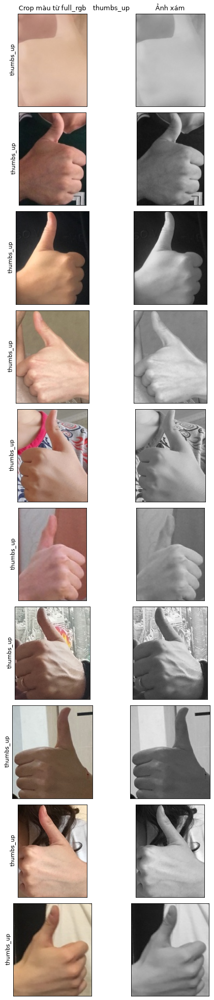

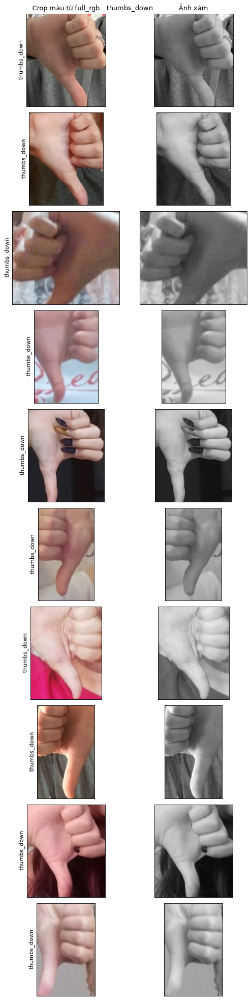

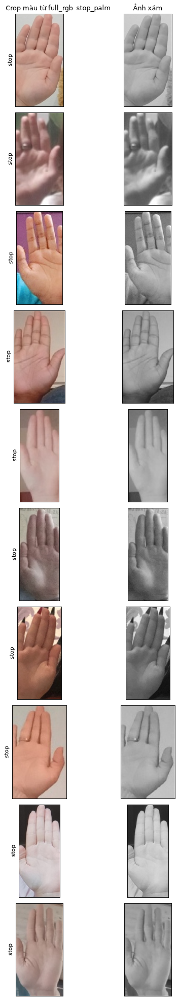

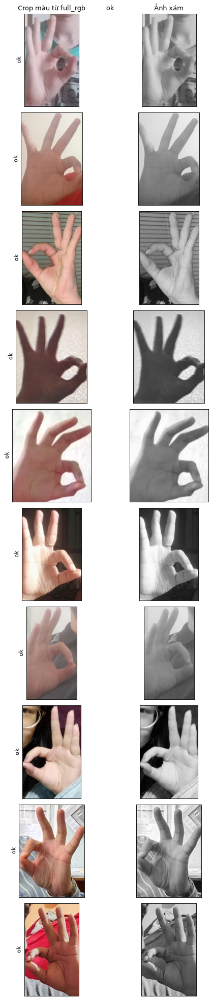

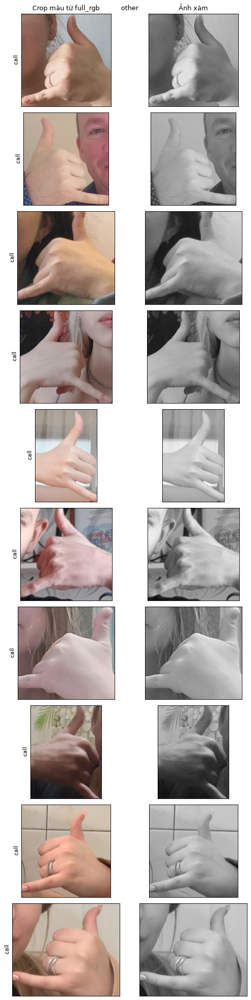

In [6]:
# So sánh 5 crop màu và ảnh xám ở mỗi lớp, lấy trực tiếp từ cache.
for label in CLASS_ORDER:
    examples = train_moi[train_moi["project_label"] == label].head(10)
    fig, axes = plt.subplots(len(examples), 2, figsize=(7, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        bgr = sample["color_image"]
        # OpenCV dùng BGR; Matplotlib hiển thị ảnh màu RGB.
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        # Ảnh xám kết hợp ba kênh màu thành một mức sáng.
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        axes[row, 0].imshow(rgb)
        axes[row, 1].imshow(gray, cmap="gray", vmin=0, vmax=255)
        axes[row, 0].set_ylabel(str(sample["source_label"]))
        for axis in axes[row]:
            axis.set_xticks([])
            axis.set_yticks([])
    axes[0, 0].set_title("Crop màu từ full_rgb")
    axes[0, 1].set_title("Ảnh xám")
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Bàn tay rõ hơn sau crop, nhưng bbox vẫn có thể cắt sát hoặc chứa nền. Ảnh xám bỏ thông tin màu trước khi trích HOG.


## 5. Resize, HOG và SVM


In [7]:
# Giữ HOG và SVM cố định để so sánh từng cách tiền xử lý.
hog_options_moi = {"image_size": (128, 128), "cell_size": (8, 8),
                   "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L2-Hys"}
svm_options_moi = {"kernel": "linear", "c": 0.1}
def xu_ly_hog_moi(image, gaussian=False):
    # Co ảnh giữ tỷ lệ trước khi tính gradient HOG.
    image = resize_grayscale_preserving_aspect(image, size=(128, 128))
    if gaussian:
        # Làm trơn cục bộ để khảo sát tác động tới gradient.
        image = cv2.GaussianBlur(image, (3, 3), 0)
    return image

def tao_tap_hog(frame, gaussian=False, xoay=False):
    images, labels = [], []
    for _, sample in frame.iterrows():
        gray = sample["image"]
        variants = [gray]
        if xoay:
            # Chỉ tạo ảnh xoay cho train; không lật nhãn ngón cái.
            h, w = gray.shape
            for angle in (-8, 8):
                matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
                variants.append(cv2.warpAffine(gray, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT))
        for variant in variants:
            images.append(xu_ly_hog_moi(variant, gaussian))
            labels.append(sample["project_label"])
    return extract_feature_matrix(images, "hog", hog_options=hog_options_moi), np.asarray(labels)


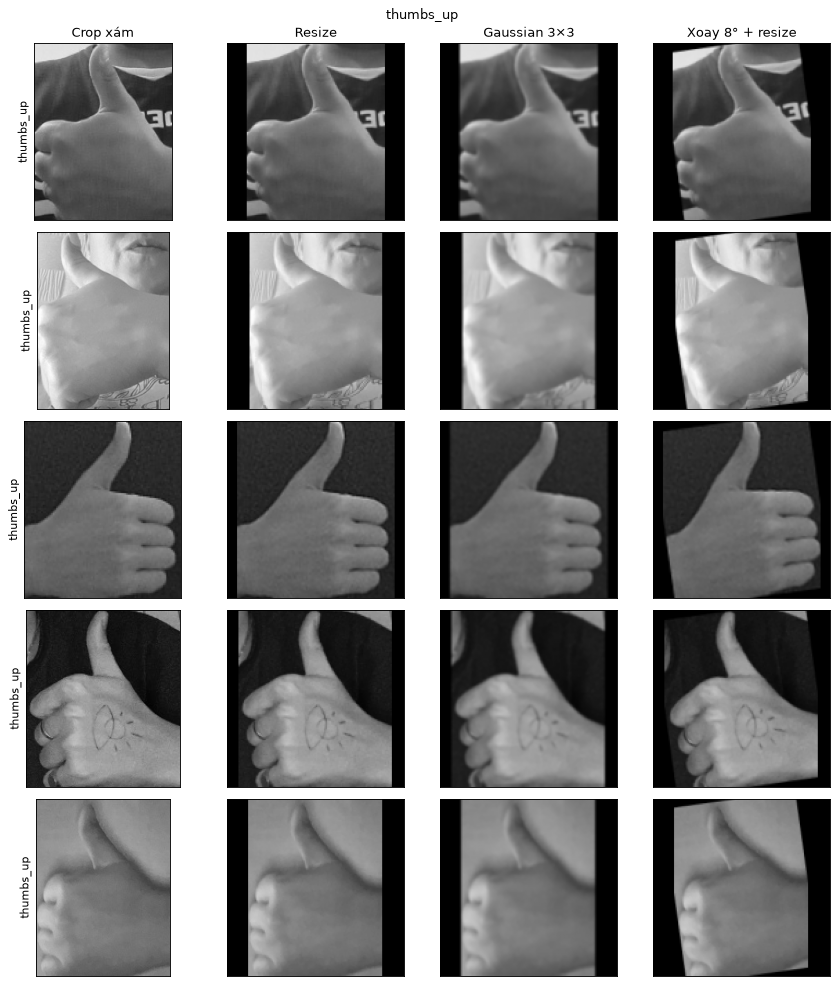

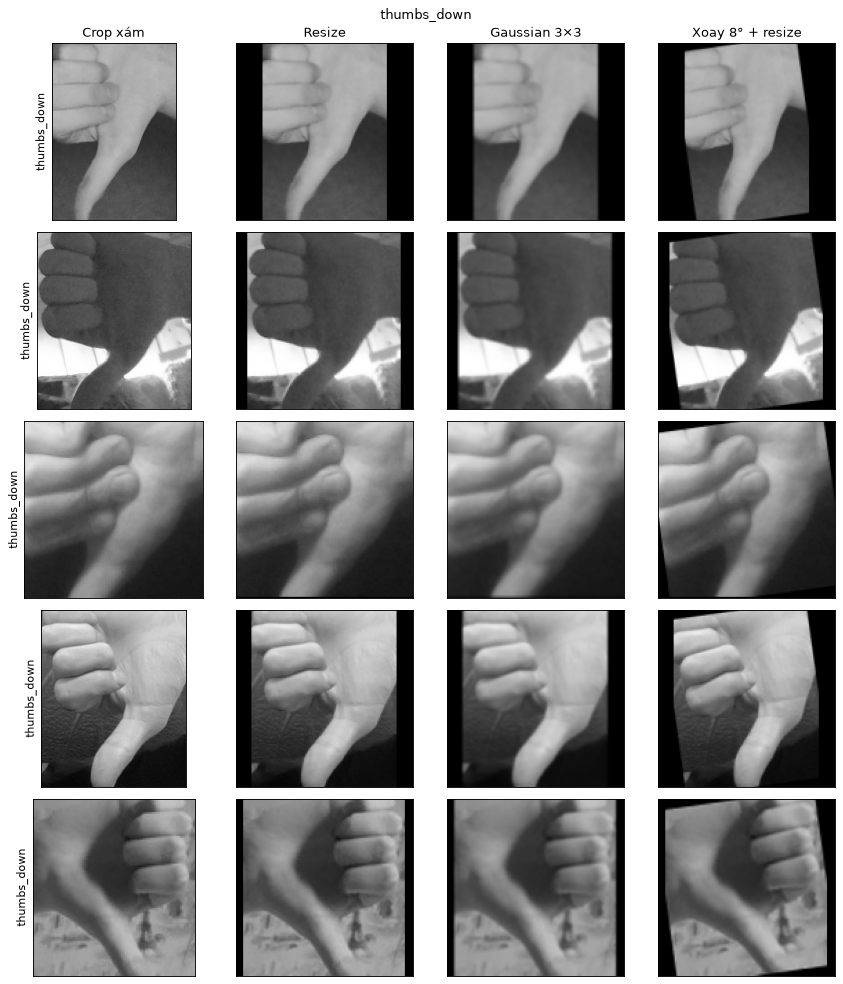

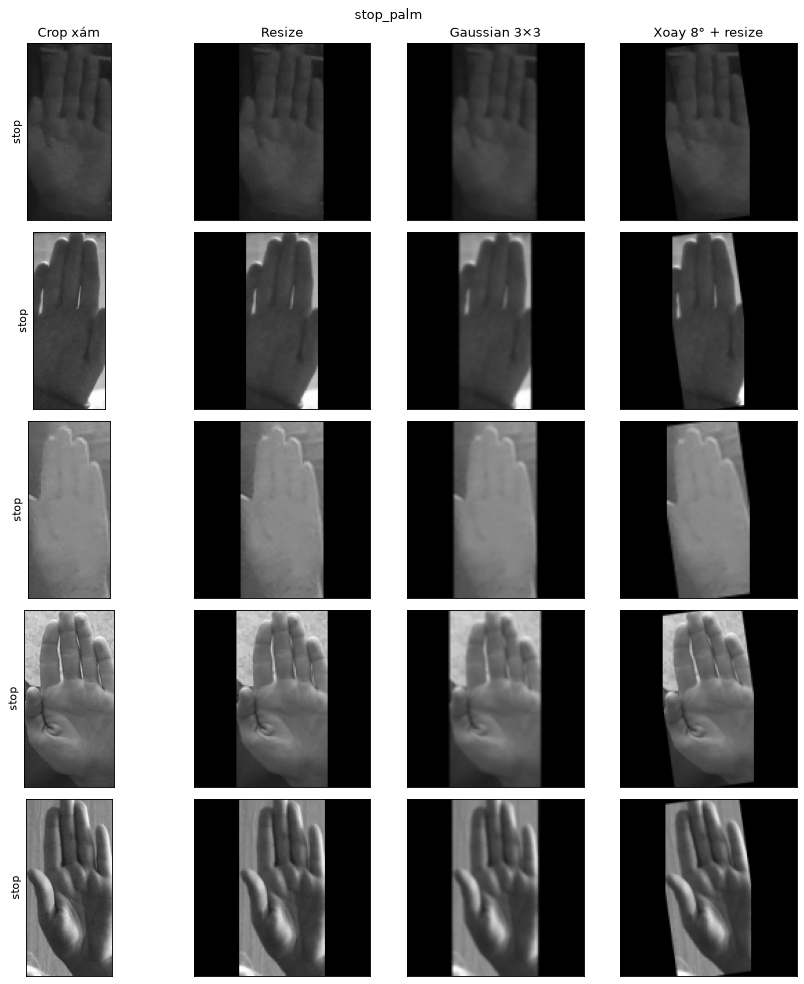

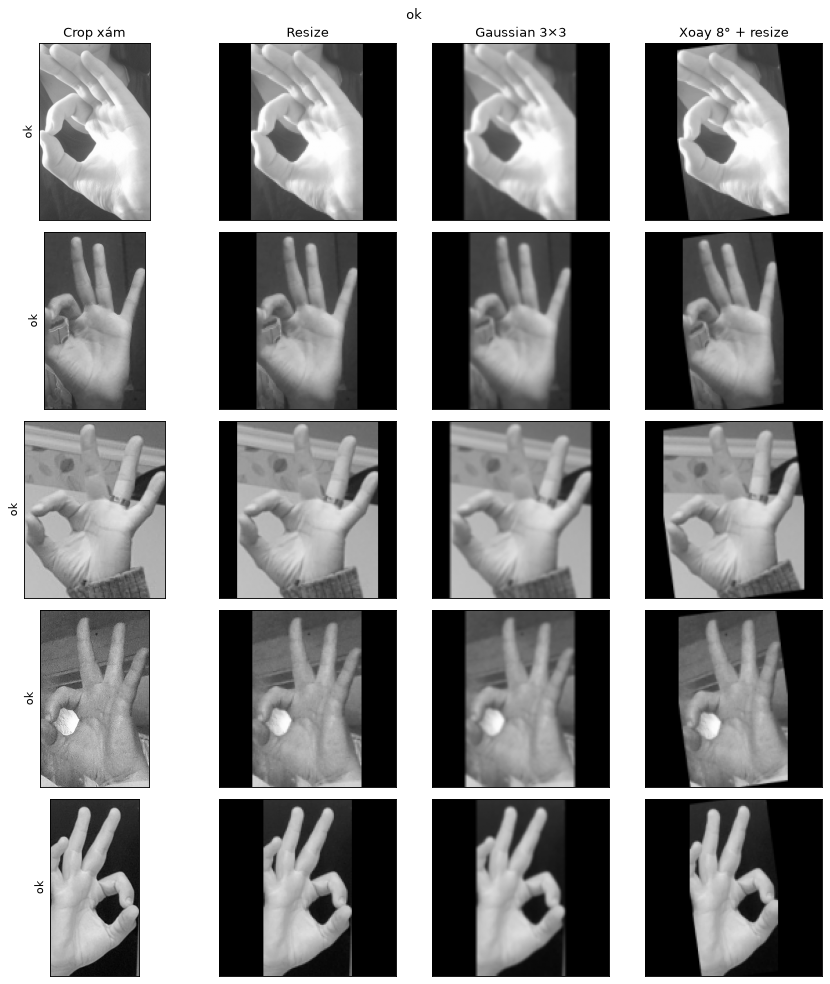

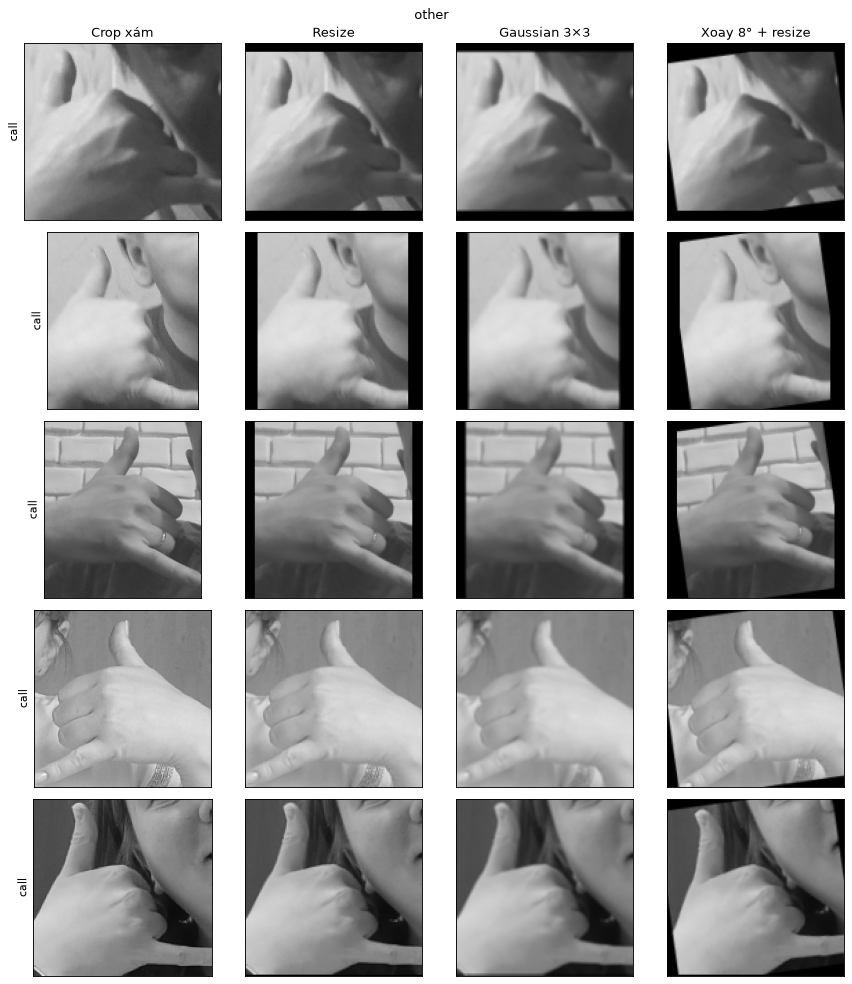

In [8]:
# Xem tác động của resize, Gaussian và xoay trên 5 ảnh validation mỗi lớp.
for label in CLASS_ORDER:
    examples = val_moi[val_moi["project_label"] == label].head(5)
    fig, axes = plt.subplots(len(examples), 4, figsize=(11, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        gray = sample["image"]
        h, w = gray.shape
        matrix = cv2.getRotationMatrix2D((w / 2, h / 2), 8, 1.0)
        rotated = cv2.warpAffine(gray, matrix, (w, h), borderMode=cv2.BORDER_CONSTANT)
        stages = [gray, xu_ly_hog_moi(gray), xu_ly_hog_moi(gray, True), xu_ly_hog_moi(rotated)]
        for axis, image in zip(axes[row], stages):
            axis.imshow(image, cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([]); axis.set_yticks([])
        axes[row, 0].set_ylabel(str(sample["source_label"]))
    for axis, title in zip(axes[0], ["Crop xám", "Resize", "Gaussian 3×3", "Xoay 8° + resize"]):
        axis.set_title(title)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Resize vẫn giữ hình chính. Ảnh xoay có góc đen và có thể mất mép; làm trơn nhẹ khó thấy khác biệt ở một số mẫu.


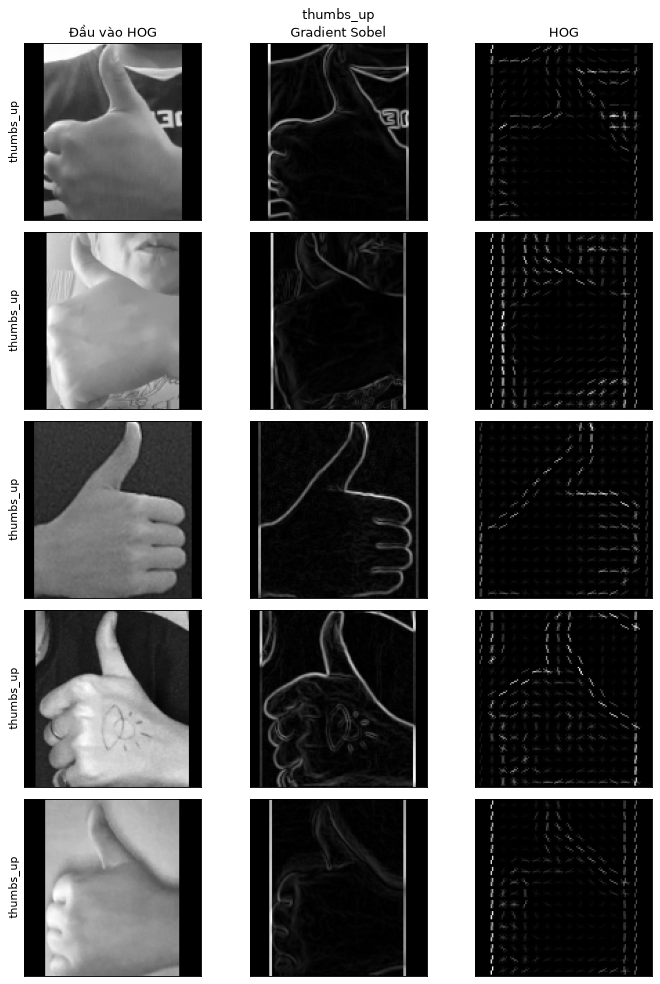

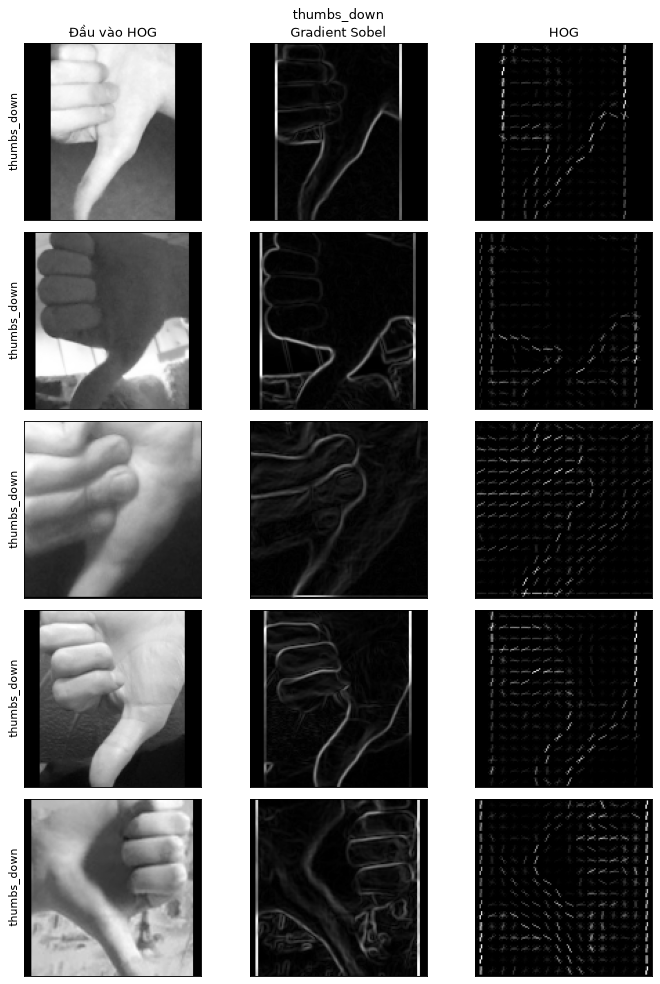

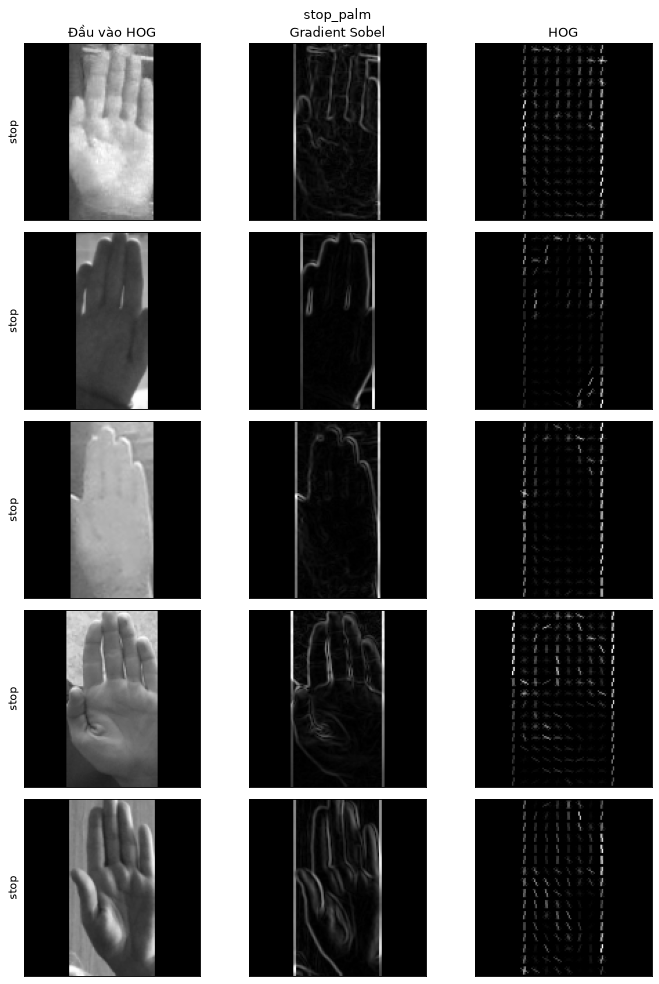

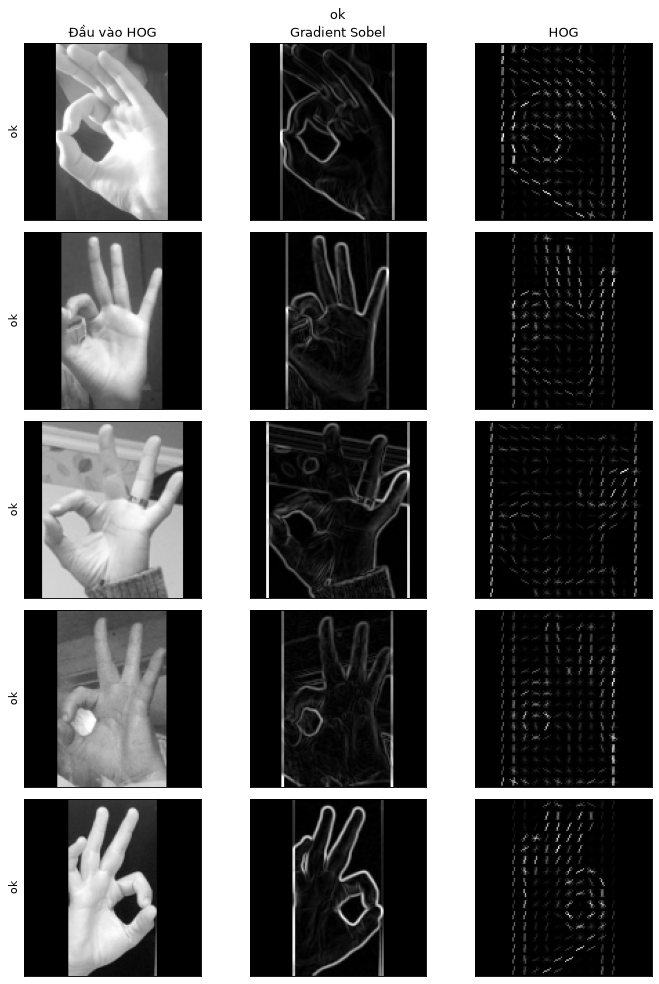

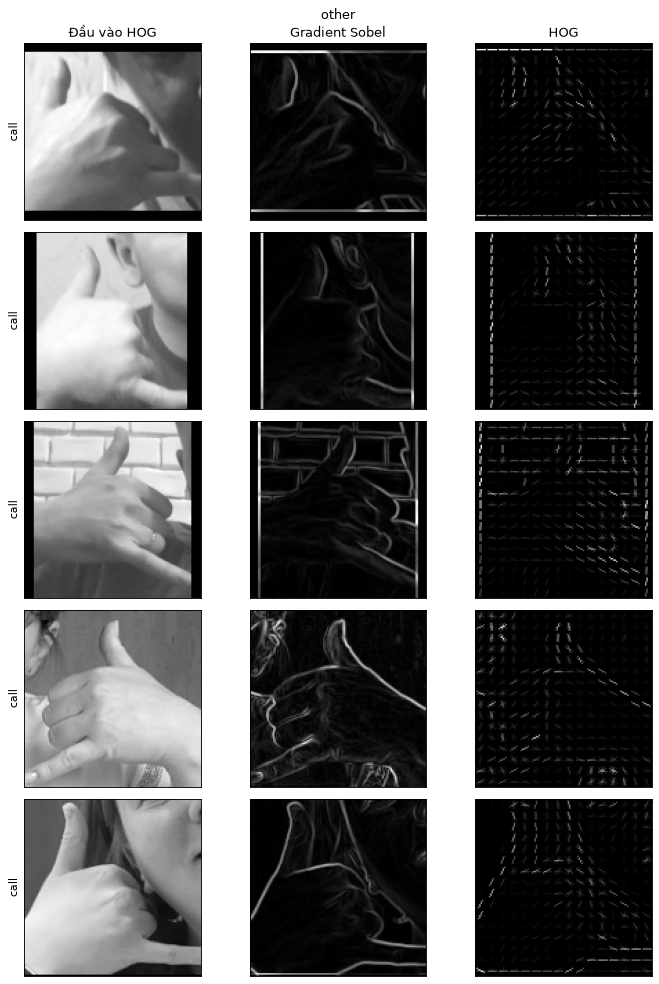

In [9]:
# Xem gradient và HOG trên đúng đầu vào 128×128 của model.
for label in CLASS_ORDER:
    examples = val_moi[val_moi["project_label"] == label].head(5)
    fig, axes = plt.subplots(len(examples), 3, figsize=(9, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        # Resize giữ tỷ lệ để các ảnh có cùng kích thước đầu vào.
        gray = resize_grayscale_preserving_aspect(sample["image"], size=(128, 128))
        # Sobel minh họa mức thay đổi độ sáng theo hai chiều.
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        magnitude = cv2.magnitude(gx, gy)
        # HOG thống kê hướng gradient trong cell và chuẩn hóa theo block.
        _, visual = hog_with_visualization(gray, orientations=9, pixels_per_cell=(8, 8),
                                            cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
        for axis, image in zip(axes[row], [gray, magnitude, visual]):
            axis.imshow(image, cmap="gray")
            axis.set_xticks([])
            axis.set_yticks([])
        axes[row, 0].set_ylabel(str(sample["source_label"]))
    for axis, title in zip(axes[0], ["Đầu vào HOG", "Gradient Sobel", "HOG"]):
        axis.set_title(title)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Gradient và HOG hiện cả cạnh bàn tay lẫn cạnh của áo hoặc nền. Sobel ở đây chỉ để minh họa gradient; phép tính bên trong thư viện HOG có thể khác.


In [10]:
# Chọn tiền xử lý và augmentation chỉ bằng validation.
hog_variants = [("goc", False, False), ("gaussian", True, False),
                ("xoay_train", False, True), ("gaussian_xoay_train", True, True)]
scores_hog_moi = []
for name, gaussian, xoay in hog_variants:
    xtr, ytr = tao_tap_hog(train_moi, gaussian, xoay)
    xval, yval = tao_tap_hog(val_moi, gaussian, False)
    model = train_svm(xtr, ytr, **svm_options_moi)
    pred = predict_svm(model, xval)
    score = evaluate_classification(yval, pred, labels=CLASS_ORDER)
    scores_hog_moi.append({"phuong_an": name, "accuracy": score["accuracy"], "macro_f1": score["macro_f1"]})
bang_hog_moi = pd.DataFrame(scores_hog_moi).sort_values("macro_f1", ascending=False, kind="stable")
print(bang_hog_moi.to_string(index=False))
best_hog_moi = next(item for item in hog_variants if item[0] == bang_hog_moi.iloc[0]["phuong_an"])
print("Chọn trên validation:", best_hog_moi[0])


          phuong_an  accuracy  macro_f1
           gaussian     0.930  0.929096
                goc     0.928  0.927786
gaussian_xoay_train     0.922  0.920200
         xoay_train     0.914  0.911735
Chọn trên validation: gaussian


**Nhận xét:** Trên validation, Gaussian đạt accuracy 93,0%, HOG gốc đạt 92,8%; chênh lệch chỉ một ảnh trong 500. Bảng test cuối dùng HOG gốc theo lưới tham số HOG, chưa đánh giá Gaussian trên test.


In [11]:
# Kiểm tra độ ổn định HOG gốc và Gaussian bằng 3 fold trên train + validation.
# StandardScaler được học lại trong từng fold; không dùng test mới.
from sklearn.model_selection import StratifiedKFold
frame_cv = pd.concat([train_moi, val_moi], ignore_index=True)
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
ket_qua_cv = []
for gaussian in (False, True):
    xcv, ycv = tao_tap_hog(frame_cv, gaussian=gaussian, xoay=False)
    for fold, (train_idx, val_idx) in enumerate(folds.split(xcv, ycv), start=1):
        model = train_svm(xcv[train_idx], ycv[train_idx], **svm_options_moi)
        pred = predict_svm(model, xcv[val_idx])
        score = evaluate_classification(ycv[val_idx], pred, labels=CLASS_ORDER)
        ket_qua_cv.append({"xu_ly": "gaussian" if gaussian else "goc", "fold": fold,
                           "accuracy": score["accuracy"], "macro_f1": score["macro_f1"]})
bang_cv = pd.DataFrame(ket_qua_cv)
print(bang_cv.to_string(index=False))
print("\nTrung bình và độ lệch chuẩn giữa 3 fold:")
print(bang_cv.groupby("xu_ly")[["accuracy", "macro_f1"]].agg(["mean", "std"]).to_string())


   xu_ly  fold  accuracy  macro_f1
     goc     1  0.913669  0.912456
     goc     2  0.917167  0.917383
     goc     3  0.918367  0.917795
gaussian     1  0.910072  0.909262
gaussian     2  0.921969  0.921885
gaussian     3  0.923169  0.922313

Trung bình và độ lệch chuẩn giữa 3 fold:
          accuracy            macro_f1          
              mean       std      mean       std
xu_ly                                           
gaussian  0.918403  0.007240  0.917820  0.007415
goc       0.916401  0.002441  0.915878  0.002971


**Nhận xét:** Điểm giữa các fold có thể dao động; kiểm tra cả ba fold trước khi kết luận tác động của Gaussian.


## 6. Canny: Gaussian, biên và contour


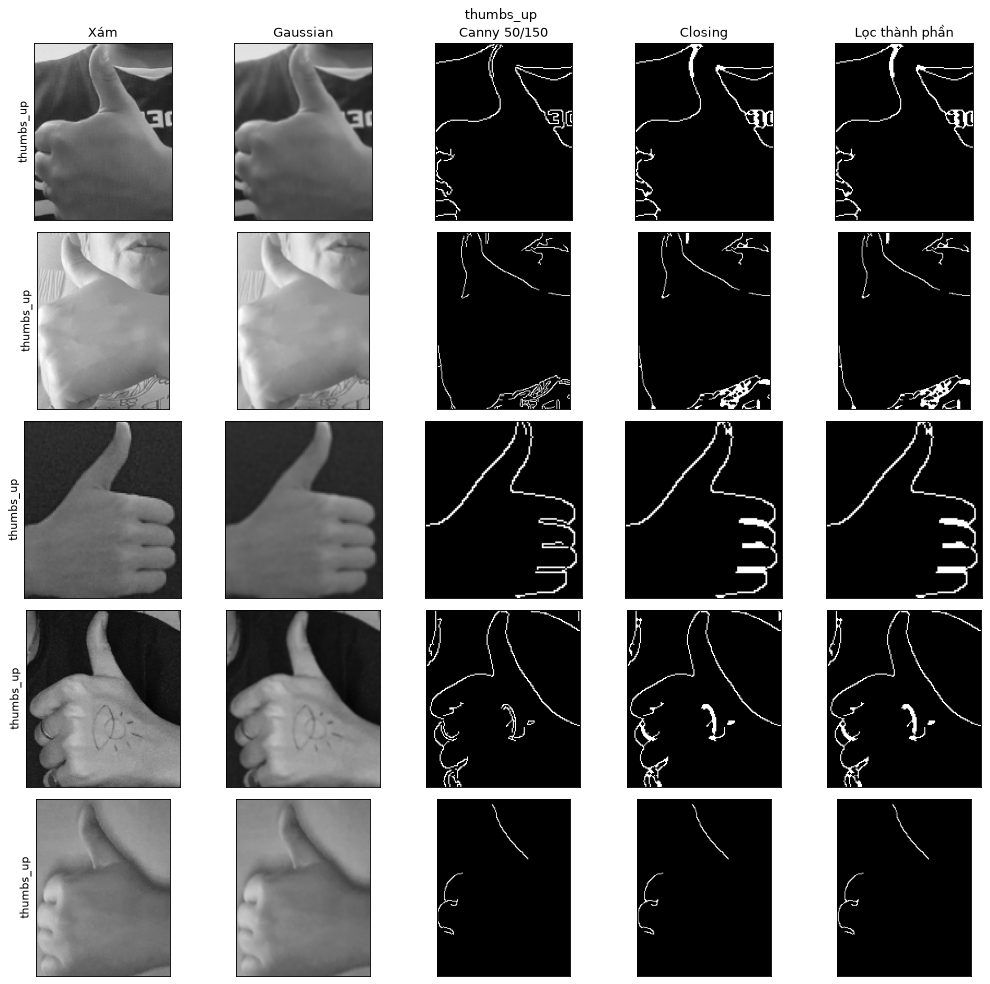

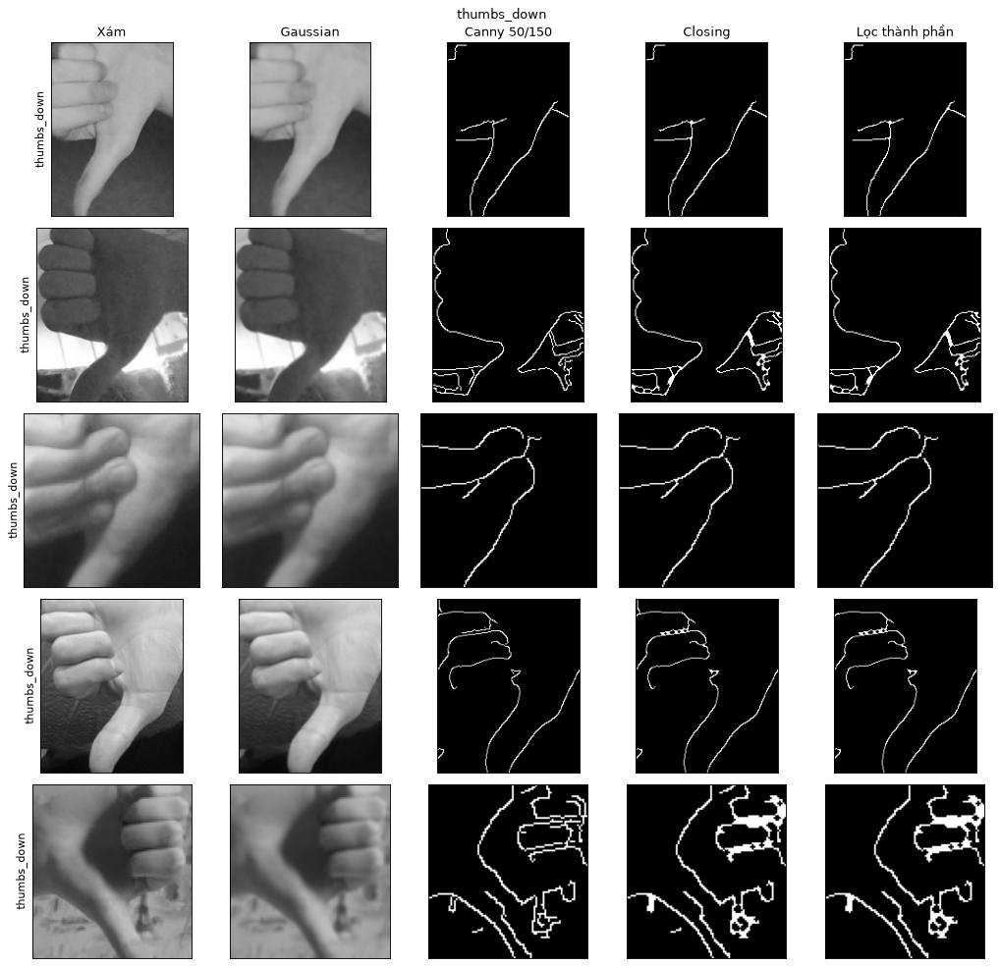

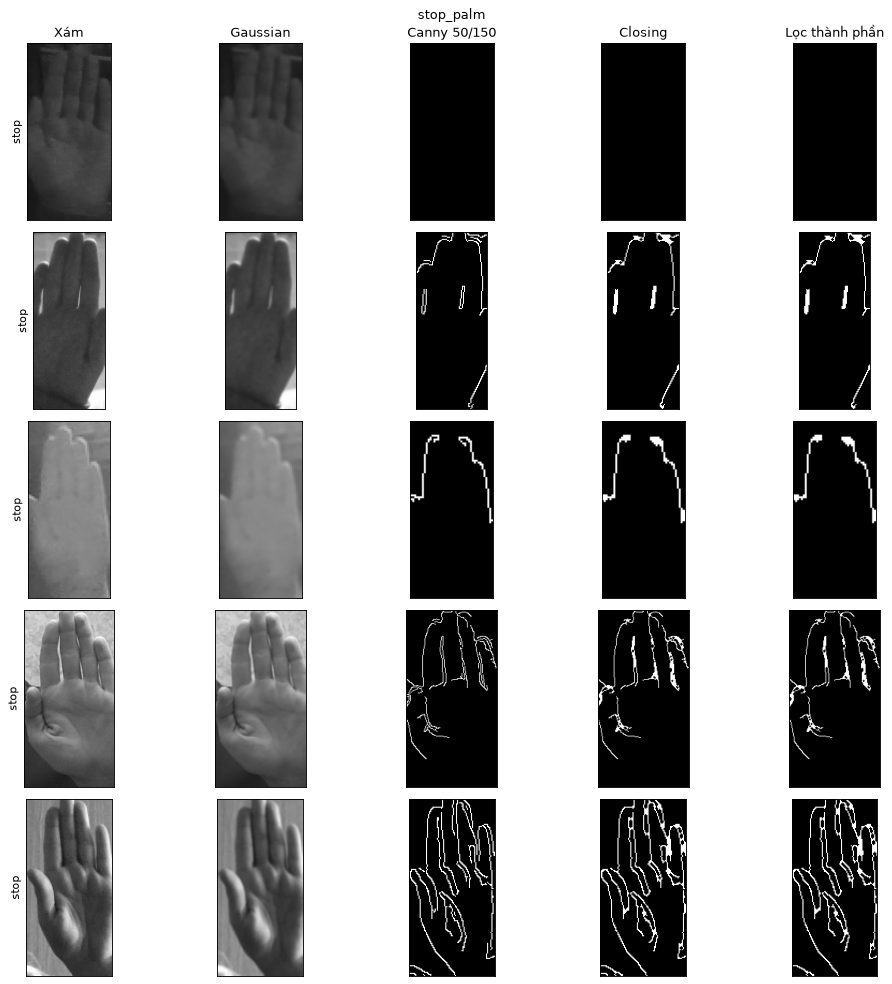

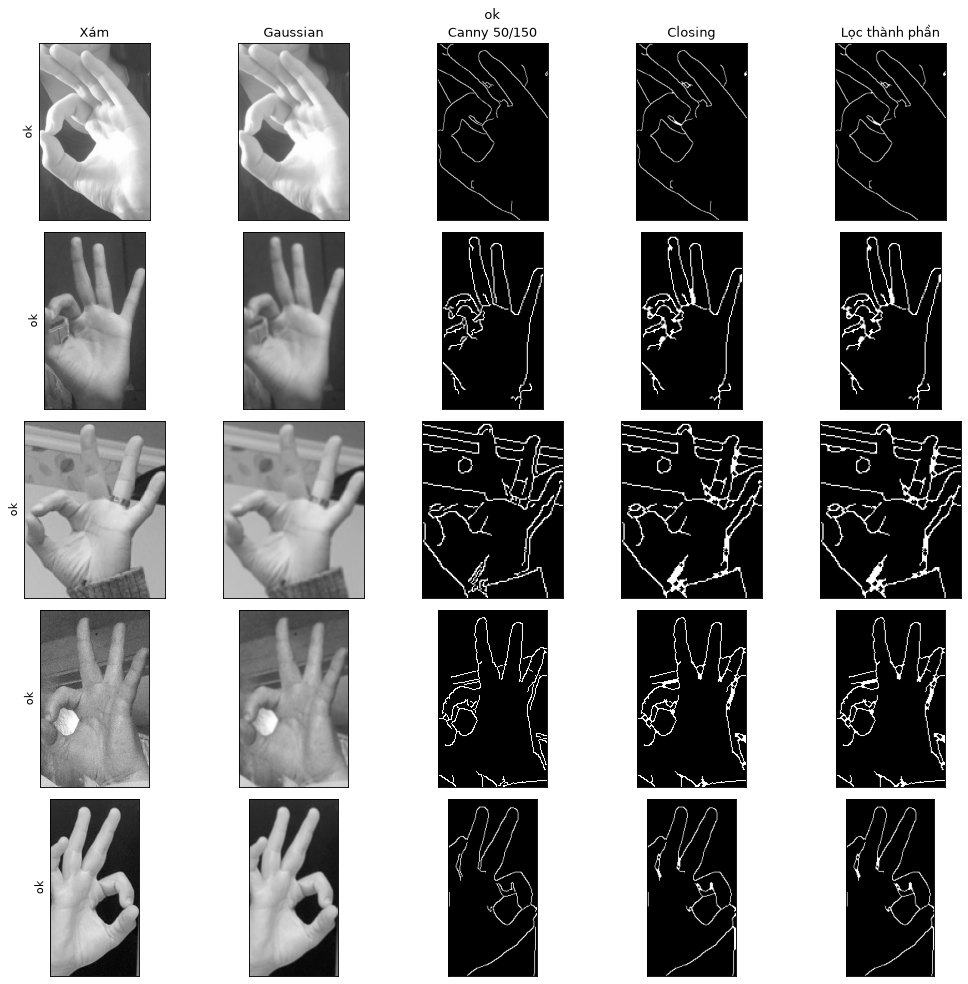

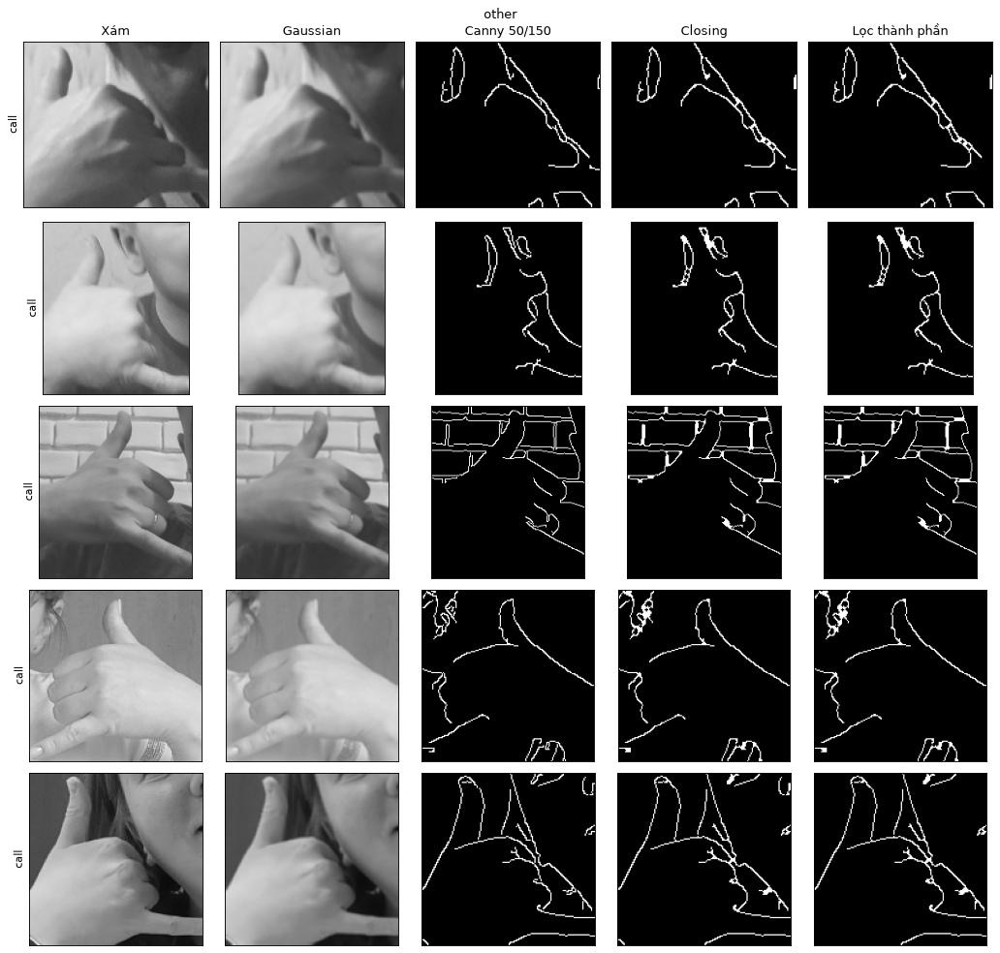

In [12]:
# Minh họa đúng các phép ảnh của nhánh Canny trên 5 mẫu mỗi lớp.
for label in CLASS_ORDER:
    examples = val_moi[val_moi["project_label"] == label].head(5)
    fig, axes = plt.subplots(len(examples), 5, figsize=(13, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        gray = sample["image"]
        # Gaussian tính trung bình có trọng số quanh mỗi pixel để làm trơn ảnh.
        blurred = cv2.GaussianBlur(gray, (3, 3), 0)
        # Canny dùng gradient, ngưỡng thấp/cao và liên kết biên mạnh với biên yếu.
        edges = cv2.Canny(blurred, 50, 150, L2gradient=True)
        # Closing = giãn rồi co, giúp nối một số khe nhỏ trên biên.
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
        # Lọc các thành phần biên quá nhỏ trước khi tìm contour.
        clean = segmentation_module.filter_small_edge_components(closed, min_area=20)
        for axis, image in zip(axes[row], [gray, blurred, edges, closed, clean]):
            axis.imshow(image, cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([]); axis.set_yticks([])
        axes[row, 0].set_ylabel(str(sample["source_label"]))
    for axis, title in zip(axes[0], ["Xám", "Gaussian", "Canny 50/150", "Closing", "Lọc thành phần"]):
        axis.set_title(title)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Canny bắt được một phần biên tay nhưng cũng có biên mặt, áo và nền. Closing chỉ nối khe nhỏ nên có ảnh đường bao vẫn bị đứt.


In [13]:
# Canny: so sánh chọn contour theo diện tích và theo vị trí gần tâm.
from src.person3_shape import chon_thanh_phan
canny_options_moi = {"low_threshold": 50, "high_threshold": 150, "blur_kernel_size": 3,
                     "closing_kernel_size": 3, "min_edge_area": 20, "min_area": 50}

def dac_trung_canny_moi(frame, gan_tam=False):
    vectors = []
    for image in frame["image"]:
        if not gan_tam:
            vectors.append(features_module.extract_canny_shape_features(image, **canny_options_moi))
            continue
        # Tìm biên, nối khe rồi chọn thành phần gần tâm ảnh.
        bgr = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
        result = segmentation_module.edge_based_segmentation(bgr, **canny_options_moi)
        mask = chon_thanh_phan(result["mask"], cach_chon="gan_tam", min_area=50)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours or max(cv2.contourArea(contour) for contour in contours) <= 0:
            vectors.append(np.zeros(len(features_module.SHAPE_FEATURE_NAMES), dtype=np.float32))
        else:
            vectors.append(features_module.extract_shape_features(mask))
    return np.asarray(vectors)

scores_canny_moi = []
for name, gan_tam in [("goc", False), ("gan_tam", True)]:
    xtr = dac_trung_canny_moi(train_moi, gan_tam)
    xval = dac_trung_canny_moi(val_moi, gan_tam)
    model = train_svm(xtr, train_moi["project_label"], kernel="linear", c=10.0)
    pred = predict_svm(model, xval)
    score = evaluate_classification(val_moi["project_label"], pred, labels=CLASS_ORDER)
    scores_canny_moi.append({"phuong_an": name, "accuracy": score["accuracy"], "macro_f1": score["macro_f1"],
                             "vector_0_train": int(np.all(xtr == 0, axis=1).sum()),
                             "vector_0_validation": int(np.all(xval == 0, axis=1).sum())})
bang_canny_moi = pd.DataFrame(scores_canny_moi).sort_values("macro_f1", ascending=False, kind="stable")
print(bang_canny_moi.to_string(index=False))
best_canny_moi = bang_canny_moi.iloc[0]["phuong_an"] == "gan_tam"


phuong_an  accuracy  macro_f1  vector_0_train  vector_0_validation
      goc     0.412  0.382680             218                   52
  gan_tam     0.350  0.336514             218                   52


**Nhận xét:** So sánh kết quả chọn vùng gần tâm và vùng lớn nhất trên validation; vector toàn 0 ít không có nghĩa mask đúng.


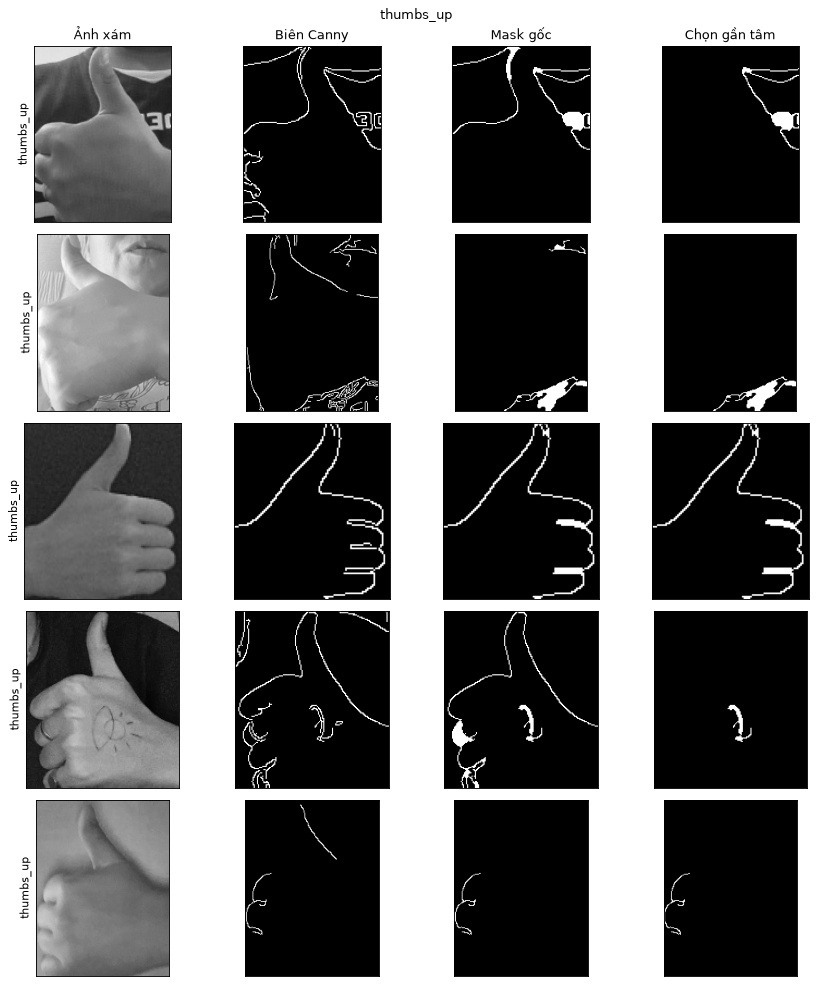

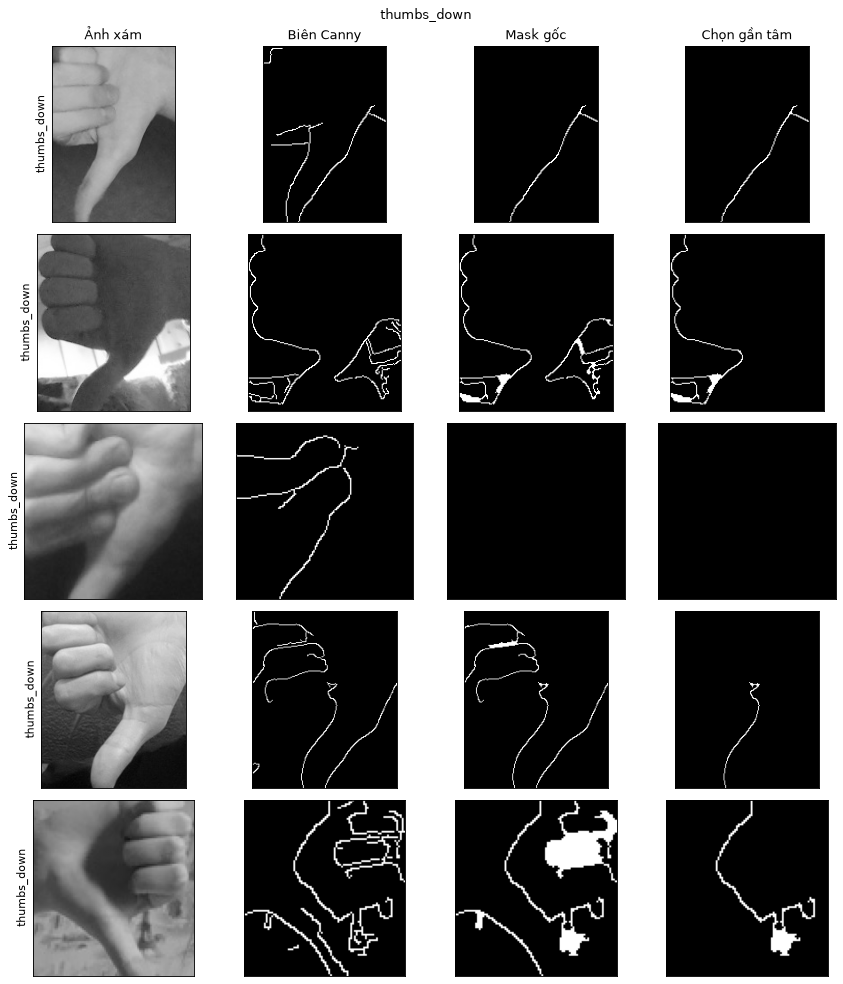

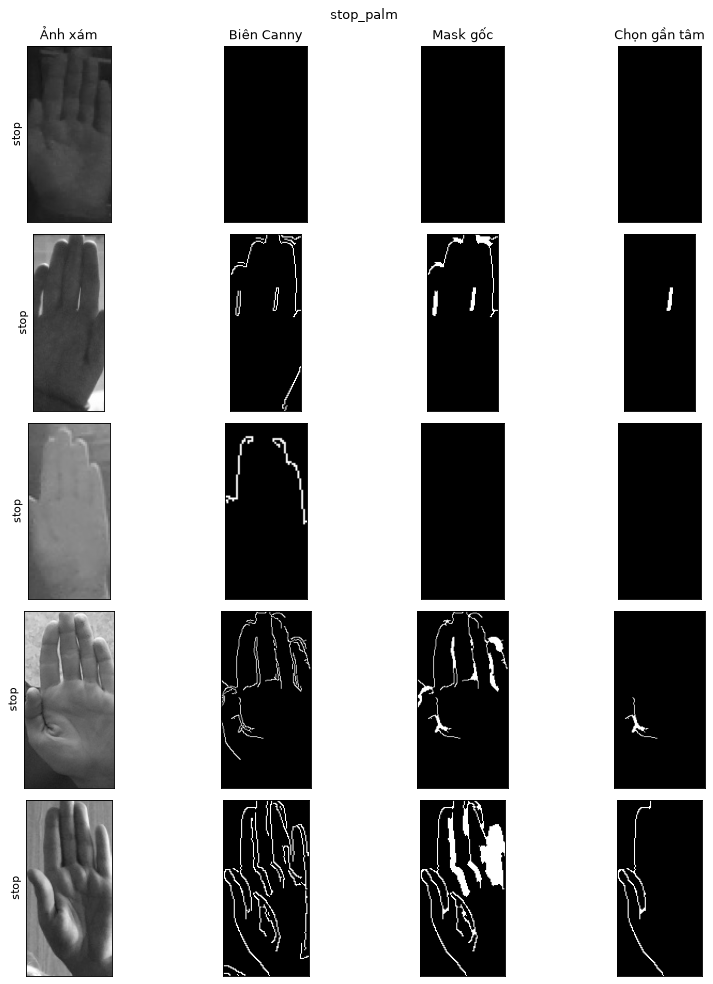

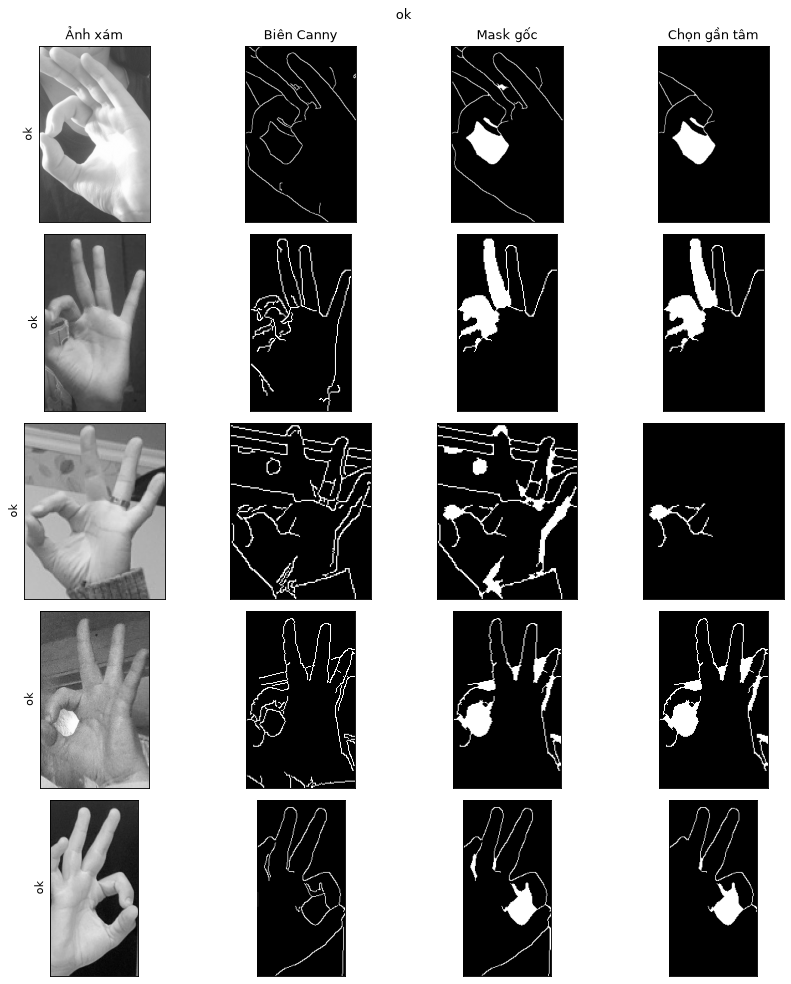

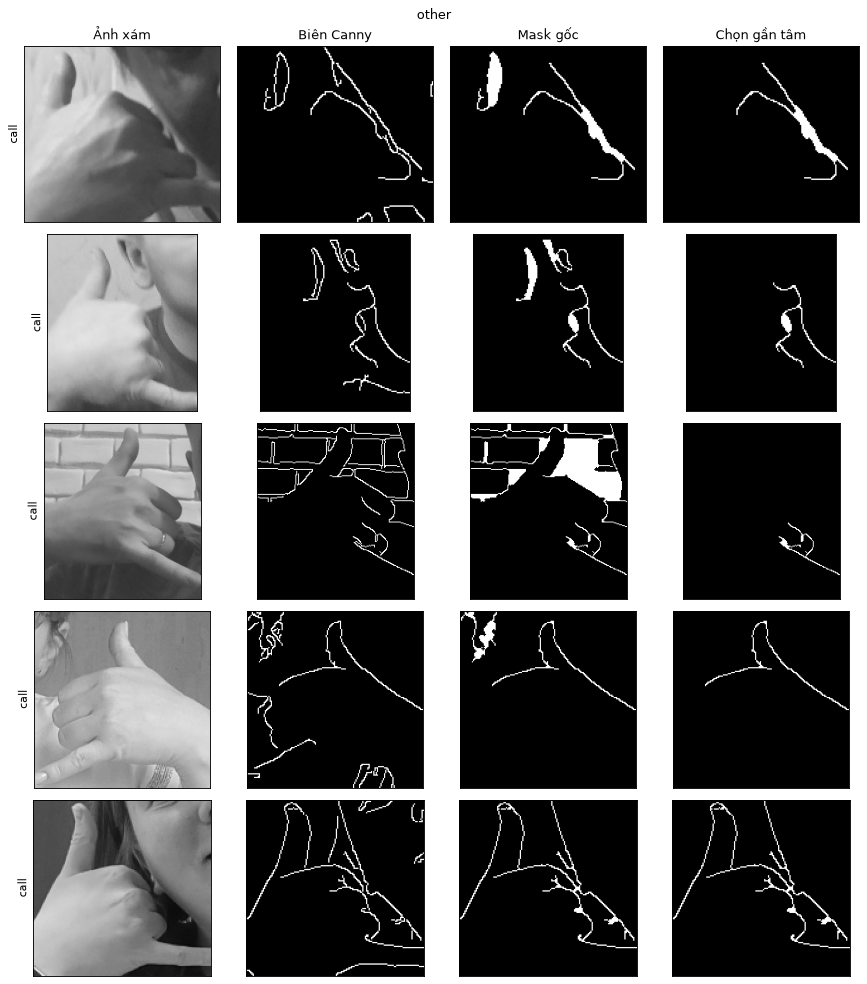

In [14]:
# Xem 5 ảnh mỗi lớp: chọn vùng gần tâm có thể nhầm nền hoặc mặt.
for label in CLASS_ORDER:
    examples = val_moi[val_moi["project_label"] == label].head(5)
    fig, axes = plt.subplots(len(examples), 4, figsize=(11, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        gray = sample["image"]
        result = segmentation_module.edge_based_segmentation(cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR), **canny_options_moi)
        center_mask = chon_thanh_phan(result["mask"], cach_chon="gan_tam", min_area=50)
        for axis, image in zip(axes[row], [gray, result["edges"], result["mask"], center_mask]):
            axis.imshow(image, cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([]); axis.set_yticks([])
        axes[row, 0].set_ylabel(str(sample["source_label"]))
    for axis, title in zip(axes[0], ["Ảnh xám", "Biên Canny", "Mask gốc", "Chọn gần tâm"]):
        axis.set_title(title)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Chọn gần tâm giúp bỏ bớt vài vùng xa, nhưng có ảnh chỉ giữ một mảnh nhỏ hoặc nhầm nền. Mask gốc trong hình gồm các contour được tô, sau đó code mới chọn contour để trích đặc trưng.


## 7. Gamma–Otsu và thử giữ lỗ


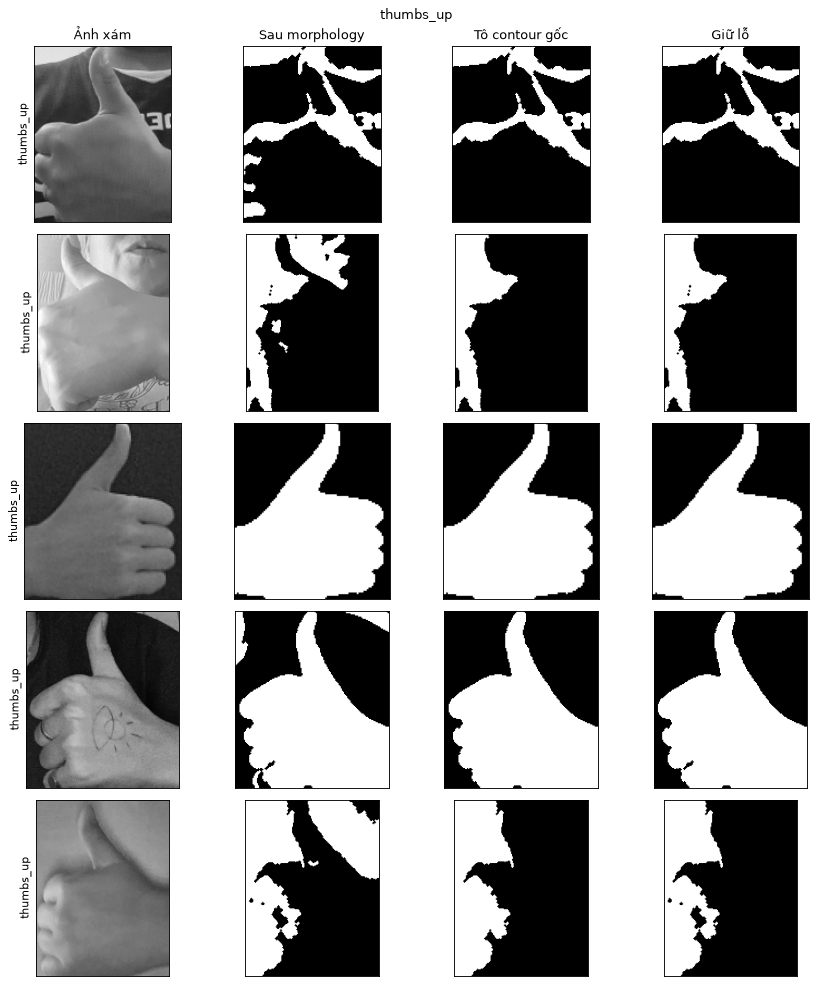

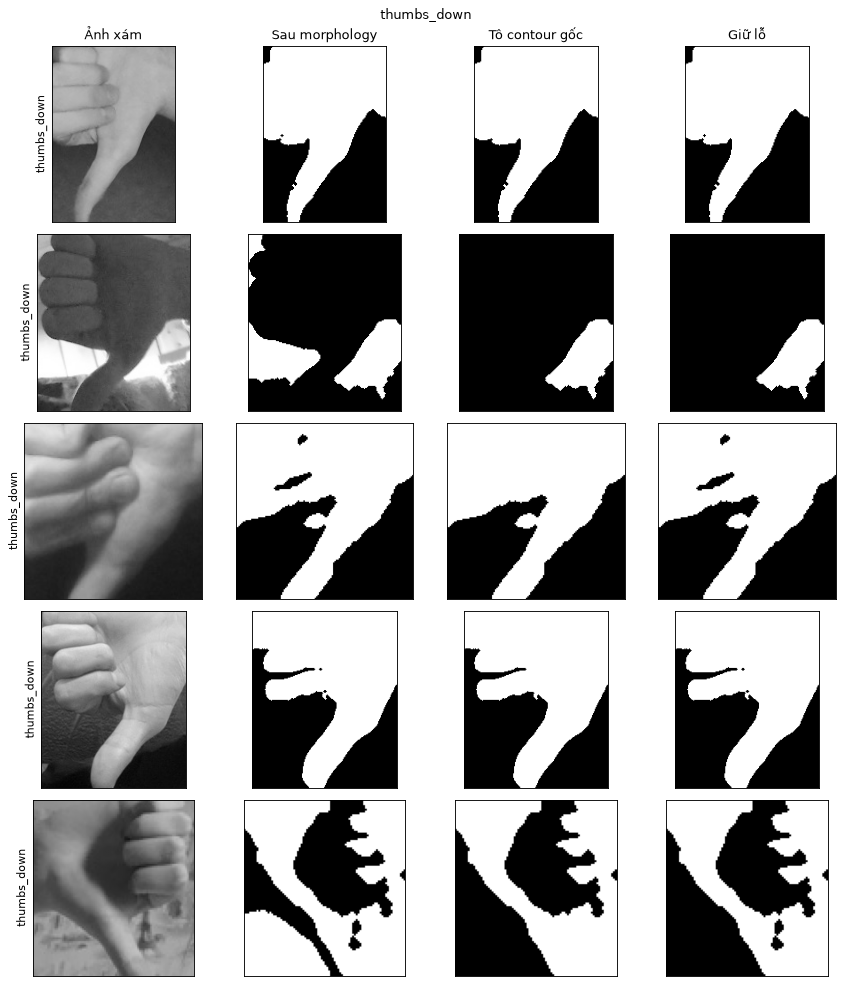

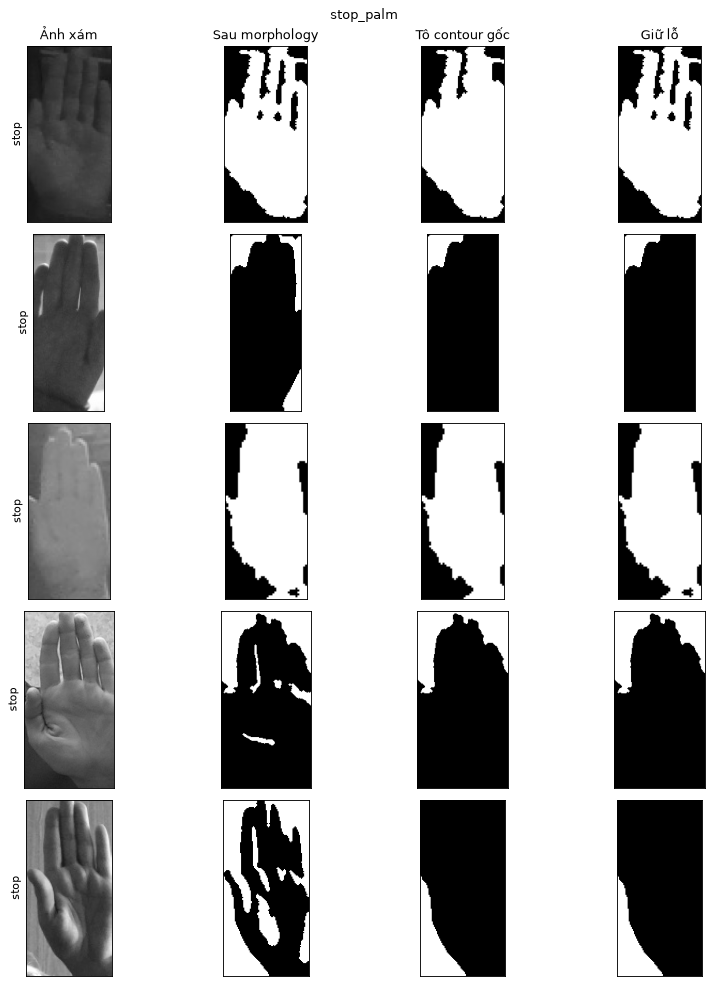

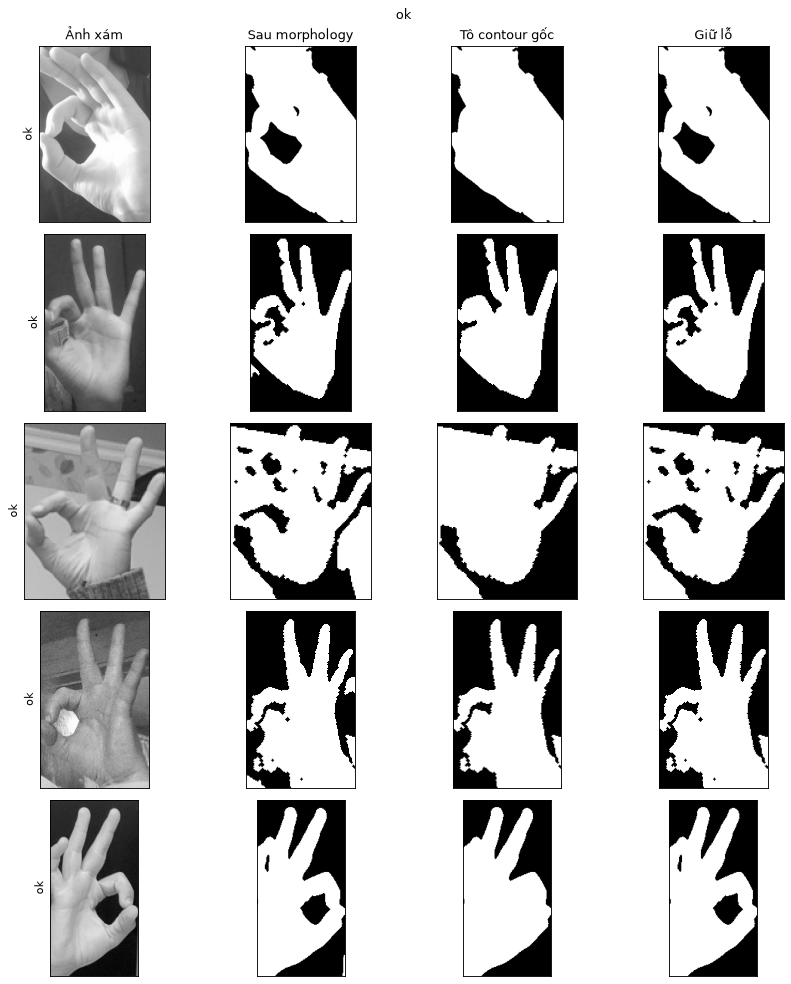

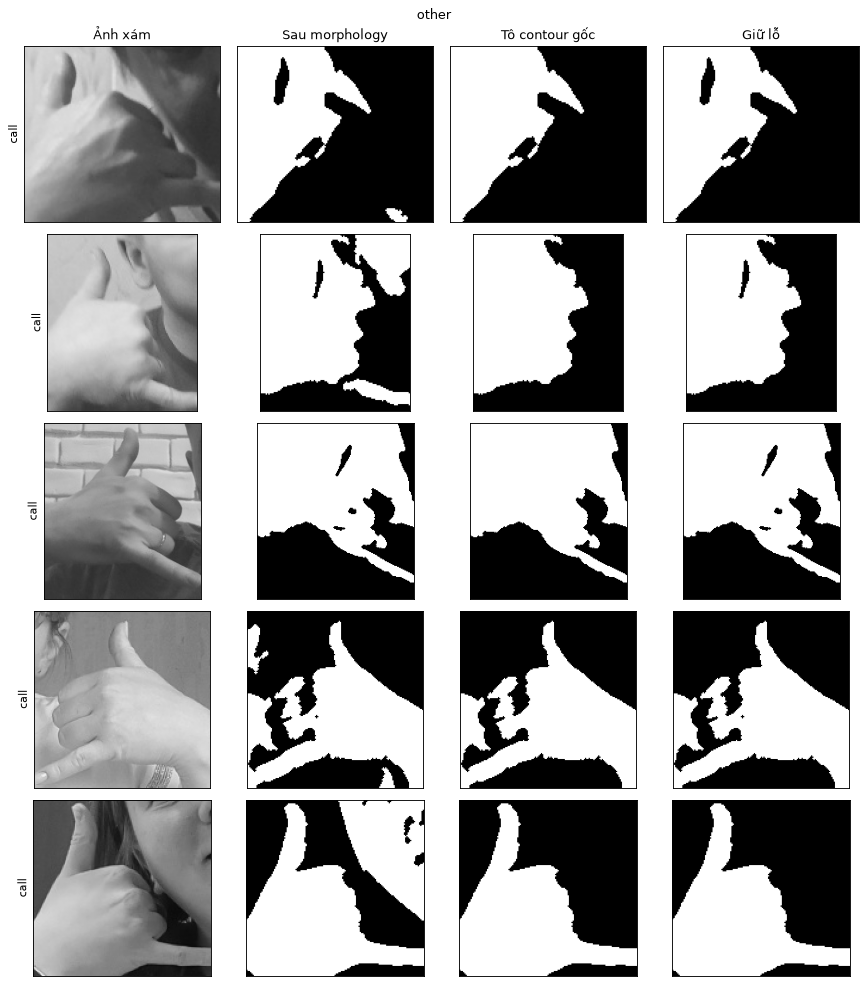

In [15]:
# So sánh mask Gamma gốc với mask giữ các lỗ còn lại sau morphology.
gamma_options_moi = {"gamma": 0.8, "foreground": "bright", "kernel_size": 3, "min_area": 50}
for label in CLASS_ORDER:
    examples = val_moi[val_moi["project_label"] == label].head(5)
    fig, axes = plt.subplots(len(examples), 4, figsize=(11, 2.5 * len(examples)), squeeze=False)
    for row, (_, sample) in enumerate(examples.iterrows()):
        # Otsu tạo mask; cách mới giữ lỗ sẵn có thay vì tô đặc contour.
        result = gamma_mask_giu_lo(sample["image"], **gamma_options_moi)
        for axis, image in zip(axes[row], [sample["image"], result["clean_mask"], result["mask"], result["mask_giu_lo"]]):
            axis.imshow(image, cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([]); axis.set_yticks([])
        axes[row, 0].set_ylabel(str(sample["source_label"]))
    for axis, title in zip(axes[0], ["Ảnh xám", "Sau morphology", "Tô contour gốc", "Giữ lỗ"]):
        axis.set_title(title)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()


**Nhận xét:** Giữ lỗ có thể giữ khoảng trống giữa các ngón, nhưng không khắc phục được trường hợp mask chọn nhầm vùng.


In [16]:
def dac_trung_gamma_moi(frame, giu_lo):
    if not giu_lo:
        return extract_feature_matrix(frame["image"], "gamma_shape", gamma_options=gamma_options_moi)
    vectors = []
    for image in frame["image"]:
        result = gamma_mask_giu_lo(image, **gamma_options_moi)
        # Nối số lỗ và tỉ lệ diện tích lỗ vào đặc trưng contour gốc.
        vectors.append(dac_trung_co_lo(result["mask_giu_lo"]))
    return np.asarray(vectors)

scores_gamma_moi = []
for name, giu_lo in [("goc", False), ("giu_lo", True)]:
    xtr = dac_trung_gamma_moi(train_moi, giu_lo)
    xval = dac_trung_gamma_moi(val_moi, giu_lo)
    model = train_svm(xtr, train_moi["project_label"], kernel="linear", c=1.0)
    pred = predict_svm(model, xval)
    score = evaluate_classification(val_moi["project_label"], pred, labels=CLASS_ORDER)
    scores_gamma_moi.append({"phuong_an": name, "accuracy": score["accuracy"], "macro_f1": score["macro_f1"]})
    print("\n", name)
    print(classification_report(val_moi["project_label"], pred, labels=CLASS_ORDER, zero_division=0))
bang_gamma_moi = pd.DataFrame(scores_gamma_moi).sort_values("macro_f1", ascending=False, kind="stable")
print(bang_gamma_moi.to_string(index=False))
best_gamma_moi = bang_gamma_moi.iloc[0]["phuong_an"] == "giu_lo"



 goc
              precision    recall  f1-score   support

   thumbs_up       0.54      0.49      0.52       100
 thumbs_down       0.46      0.48      0.47       100
   stop_palm       0.50      0.62      0.55       100
          ok       0.45      0.59      0.51       100
       other       0.38      0.20      0.26       100

    accuracy                           0.48       500
   macro avg       0.47      0.48      0.46       500
weighted avg       0.47      0.48      0.46       500


 giu_lo
              precision    recall  f1-score   support

   thumbs_up       0.56      0.53      0.55       100
 thumbs_down       0.49      0.49      0.49       100
   stop_palm       0.52      0.64      0.57       100
          ok       0.50      0.61      0.55       100
       other       0.41      0.25      0.31       100

    accuracy                           0.50       500
   macro avg       0.50      0.50      0.49       500
weighted avg       0.50      0.50      0.49       500

phuong_

**Nhận xét:** Hai cách thay đổi đồng thời mask và đặc trưng lỗ, nên chưa thể quy chênh lệch cho riêng một bước.


## 8. Khảo sát tham số trên validation

Tìm cấu hình trên validation theo đúng ID của nhóm trưởng trước khi đánh giá official test.


### 8.1 Các tham số cố định

- Seed 42 để có thể lặp lại cách chia; seed không phải tham số giúp model tốt hơn. CSV nhóm trưởng có 400/100/200 ảnh mỗi lớp trong train/validation/test; seed và lựa chọn mẫu được ghi trong CSV.
- Xoay ±8° là mức thử nhẹ nhằm khảo sát thay đổi hướng, không bảo đảm luôn giữ được toàn bộ tay hoặc phù hợp mọi nhãn. Ba fold là kiểm tra độ ổn định sơ bộ, không phải số fold tối ưu.
- Ngưỡng diện tích 20/50 pixel là các mức lọc thử để bỏ thành phần nhỏ, có thể xóa nét tay; chưa khảo sát riêng chúng. Chọn vùng gần tâm dựa trên giả định tay thường gần giữa crop, có thể nhầm với nền hoặc mặt.
- Gaussian 3×3, gamma 0,8, kernel hình thái 3×3 và SVM C được dùng làm cấu hình ban đầu để đối chiếu. Các bảng sau khảo sát một số giá trị, không chứng minh lựa chọn tốt nhất trên mọi ảnh.
- `min_hole_area=4` bỏ các lỗ rất nhỏ khi đếm, còn nhân ellipse là lựa chọn cấu trúc hình thái đang dùng; hai giá trị này chưa được so sánh riêng.
- Train và validation thuộc official train V1; test thuộc official test V1 theo CSV của nhóm trưởng.
- Ảnh grayscale và SVM tuyến tính là phạm vi baseline cổ điển; notebook hiện chưa chứng minh chúng tốt hơn mọi hệ màu hay mọi kernel.


In [17]:
# Dùng cùng train và validation; chỉ tính đặc trưng một lần cho mỗi cấu hình.
def tim_cau_hinh_tv3(method, options_list, cac_c):
    rows = []
    ytr = train_moi["project_label"].to_numpy()
    yval = val_moi["project_label"].to_numpy()
    for options in options_list:
        if method == "hog":
            # Resize, tính gradient, histogram theo cell và chuẩn hóa block.
            xtr = extract_feature_matrix(train_moi["image"], "hog", hog_options=options)
            xval = extract_feature_matrix(val_moi["image"], "hog", hog_options=options)
        elif method == "gamma":
            # Gamma → Otsu → morphology → contour ngoài → Hu và hình học.
            xtr = extract_feature_matrix(train_moi["image"], "gamma_shape", gamma_options=options)
            xval = extract_feature_matrix(val_moi["image"], "gamma_shape", gamma_options=options)
        else:
            # Canny → mask → chọn thành phần gần tâm → Hu và hình học.
            def canny_vector(frame):
                vectors = []
                for gray in frame["image"]:
                    bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
                    result = segmentation_module.edge_based_segmentation(bgr, **options)
                    mask = chon_thanh_phan(result["mask"], cach_chon="gan_tam", min_area=options["min_area"])
                    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    if not contours or max(cv2.contourArea(c) for c in contours) <= 0:
                        vectors.append(np.zeros(len(features_module.SHAPE_FEATURE_NAMES), dtype=np.float32))
                    else:
                        vectors.append(features_module.extract_shape_features(mask))
                return np.asarray(vectors)
            xtr, xval = canny_vector(train_moi), canny_vector(val_moi)
        for c in cac_c:
            # SVM học bộ chuẩn hóa chỉ từ train, rồi dự đoán validation.
            model = train_svm(xtr, ytr, kernel="linear", c=c)
            pred = predict_svm(model, xval)
            score = evaluate_classification(yval, pred, labels=CLASS_ORDER)
            rows.append({"tham_so": str(options), "C": c, "accuracy": score["accuracy"],
                         "macro_f1": score["macro_f1"],
                         "vector_0_train": int(np.all(xtr == 0, axis=1).sum()),
                         "vector_0_val": int(np.all(xval == 0, axis=1).sum())})
    return pd.DataFrame(rows).sort_values("macro_f1", ascending=False, kind="stable").reset_index(drop=True)

# Các giá trị C được thử theo thang log để xem ảnh hưởng của mức phạt SVM.
cac_c = [0.1, 1.0, 10.0, 100.0]


### 8.2 Chọn kích thước và tham số HOG

So sánh 64×64 với 128×128, cell 8/16, block 2/3, 9/12 hướng và chuẩn hóa L1/L2/L2-Hys trong các cấu hình bên dưới. 9 hướng, cell 8 và block 2 là cấu hình bài lab; các mức còn lại dùng để so sánh, không phải tìm kiếm toàn bộ tổ hợp.


In [18]:
HOG_SEARCH = [
    {"image_size": (64, 64), "cell_size": (8, 8), "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L2-Hys"},
    {"image_size": (64, 64), "cell_size": (8, 8), "cells_per_block": (2, 2), "orientations": 12, "block_norm": "L2-Hys"},
    {"image_size": (64, 64), "cell_size": (16, 16), "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L2-Hys"},
    {"image_size": (64, 64), "cell_size": (8, 8), "cells_per_block": (3, 3), "orientations": 9, "block_norm": "L2-Hys"},
    {"image_size": (64, 64), "cell_size": (8, 8), "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L2"},
    {"image_size": (64, 64), "cell_size": (8, 8), "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L1"},
    {"image_size": (128, 128), "cell_size": (8, 8), "cells_per_block": (2, 2), "orientations": 9, "block_norm": "L2-Hys"},
]
bang_tim_hog = tim_cau_hinh_tv3("hog", HOG_SEARCH, cac_c)
print(bang_tim_hog.to_string(index=False))
print("\nTốt nhất trong danh sách HOG theo validation:")
print(bang_tim_hog.head(1).to_string(index=False))
print("Nhận xét: Các cấu hình hòa điểm cần được xem cùng nhau; chưa kết luận trên test mới.")


                                                                                                              tham_so     C  accuracy  macro_f1  vector_0_train  vector_0_val
{'image_size': (128, 128), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 9, 'block_norm': 'L2-Hys'}   0.1     0.928  0.927786               0             0
{'image_size': (128, 128), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 9, 'block_norm': 'L2-Hys'}   1.0     0.928  0.927786               0             0
{'image_size': (128, 128), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 9, 'block_norm': 'L2-Hys'}  10.0     0.928  0.927786               0             0
{'image_size': (128, 128), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 9, 'block_norm': 'L2-Hys'} 100.0     0.928  0.927786               0             0
 {'image_size': (64, 64), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 12, 'block_norm': 'L2-Hys'}   0.1     0.

**Nhận xét:** HOG 128×128, cell 8, block 2, 9 hướng và L2-Hys đạt Macro-F1 validation 0,928. Bốn giá trị C hòa điểm; C=0,1 được lấy theo thứ tự, không chứng minh tốt hơn các C còn lại.


### 8.2 Vì sao cần resize crop bbox?

Crop bbox có kích thước và tỷ lệ khác nhau. HOG tạo vector có cùng số chiều để đưa vào SVM, nên ảnh cần được chuẩn hóa kích thước. Hàm trong `src/features.py` giữ tỷ lệ, đặt ảnh vào canvas 128×128 và đệm phần trống; không kéo méo ảnh.


In [19]:
# Kiểm tra kích thước crop bbox trước khi chuẩn hóa về cùng canvas.
box_stats = split_moi.assign(
    bbox_width=split_moi.crop_bbox_x2-split_moi.crop_bbox_x1,
    bbox_height=split_moi.crop_bbox_y2-split_moi.crop_bbox_y1,
)
print("Crop bbox width:")
print(box_stats.bbox_width.describe(percentiles=[0.1,0.5,0.9]).to_string())
print("\nCrop bbox height:")
print(box_stats.bbox_height.describe(percentiles=[0.1,0.5,0.9]).to_string())
print("\nKích thước HOG cố định:", hog_options_moi["image_size"])


Crop bbox width:
count    3500.000000
mean       98.919714
std        38.768166
min        23.000000
10%        53.000000
50%        95.000000
90%       150.000000
max       293.000000

Crop bbox height:
count    3500.000000
mean      147.544000
std        46.838952
min        34.000000
10%        93.000000
50%       142.000000
90%       212.000000
max       350.000000

Kích thước HOG cố định: (128, 128)


### 8.3 Khảo sát ngưỡng Canny và morphology

Thử ba cặp ngưỡng, Gaussian 3/5 và closing 3/5 để xem đánh đổi giữa biên yếu, nhiễu và nối khe. Các cấu hình dùng cùng cách chọn thành phần gần tâm; diện tích 20/50 cố định nên chưa kết luận được tác động của các ngưỡng diện tích này.


In [20]:
CANNY_SEARCH = [
    {"low_threshold": 30, "high_threshold": 90, "blur_kernel_size": 3, "closing_kernel_size": 3, "min_edge_area": 20, "min_area": 50},
    {"low_threshold": 50, "high_threshold": 150, "blur_kernel_size": 3, "closing_kernel_size": 3, "min_edge_area": 20, "min_area": 50},
    {"low_threshold": 80, "high_threshold": 160, "blur_kernel_size": 3, "closing_kernel_size": 3, "min_edge_area": 20, "min_area": 50},
    {"low_threshold": 50, "high_threshold": 150, "blur_kernel_size": 5, "closing_kernel_size": 3, "min_edge_area": 20, "min_area": 50},
    {"low_threshold": 50, "high_threshold": 150, "blur_kernel_size": 3, "closing_kernel_size": 5, "min_edge_area": 20, "min_area": 50},
]
bang_tim_canny = tim_cau_hinh_tv3("canny", CANNY_SEARCH, cac_c)
print(bang_tim_canny.to_string(index=False))
print("\nTốt nhất trong danh sách Canny theo validation:")
print(bang_tim_canny.head(1).to_string(index=False))
print("Nhận xét: Vector 0 không cho biết mask không rỗng đã chọn đúng bàn tay hay chưa.")


                                                                                                                           tham_so     C  accuracy  macro_f1  vector_0_train  vector_0_val
 {'low_threshold': 30, 'high_threshold': 90, 'blur_kernel_size': 3, 'closing_kernel_size': 3, 'min_edge_area': 20, 'min_area': 50}   0.1     0.426  0.397415              38             8
 {'low_threshold': 30, 'high_threshold': 90, 'blur_kernel_size': 3, 'closing_kernel_size': 3, 'min_edge_area': 20, 'min_area': 50}   1.0     0.414  0.386579              38             8
 {'low_threshold': 30, 'high_threshold': 90, 'blur_kernel_size': 3, 'closing_kernel_size': 3, 'min_edge_area': 20, 'min_area': 50} 100.0     0.408  0.378585              38             8
 {'low_threshold': 30, 'high_threshold': 90, 'blur_kernel_size': 3, 'closing_kernel_size': 3, 'min_edge_area': 20, 'min_area': 50}  10.0     0.404  0.373804              38             8
{'low_threshold': 50, 'high_threshold': 150, 'blur_kernel_size': 

**Nhận xét:** Canny 30/90, Gaussian 3×3, closing 3×3, chọn gần tâm và C=0,1 đạt Macro-F1 validation khoảng 0,397. Đây là kết quả tốt nhất trong danh sách đã thử.


### 8.4 Khảo sát gamma và phía sáng/tối

Thử gamma 0,6–1,2 để so sánh làm sáng, giữ nguyên và làm tối; thử vùng sáng/tối cùng kernel 3/5. Các cấu hình bên dưới dùng Gamma gốc với contour ngoài, không phải biến thể giữ lỗ.


In [21]:
GAMMA_SEARCH = [
    {"gamma": 0.6, "foreground": "bright", "kernel_size": 3, "min_area": 50},
    {"gamma": 0.8, "foreground": "bright", "kernel_size": 3, "min_area": 50},
    {"gamma": 1.0, "foreground": "bright", "kernel_size": 3, "min_area": 50},
    {"gamma": 1.2, "foreground": "bright", "kernel_size": 3, "min_area": 50},
    {"gamma": 0.8, "foreground": "dark", "kernel_size": 3, "min_area": 50},
    {"gamma": 1.0, "foreground": "dark", "kernel_size": 3, "min_area": 50},
    {"gamma": 0.8, "foreground": "bright", "kernel_size": 5, "min_area": 50},
]
bang_tim_gamma = tim_cau_hinh_tv3("gamma", GAMMA_SEARCH, cac_c)
print(bang_tim_gamma.to_string(index=False))
print("\nTốt nhất trong danh sách Gamma theo validation:")
print(bang_tim_gamma.head(1).to_string(index=False))
print("Nhận xét: Chọn vùng sáng hoặc tối không bảo đảm tách đúng tay khỏi nền.")


                                                                 tham_so     C  accuracy  macro_f1  vector_0_train  vector_0_val
{'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 5, 'min_area': 50}   0.1     0.490  0.478431               1             0
{'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 3, 'min_area': 50}   0.1     0.488  0.471330               0             0
{'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 5, 'min_area': 50}  10.0     0.486  0.471062               1             0
{'gamma': 1.0, 'foreground': 'bright', 'kernel_size': 3, 'min_area': 50}   1.0     0.488  0.470763               3             0
{'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 5, 'min_area': 50}   1.0     0.486  0.470585               1             0
{'gamma': 1.0, 'foreground': 'bright', 'kernel_size': 3, 'min_area': 50}  10.0     0.488  0.469799               3             0
{'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 3, 'min_area': 50}  10.0     0.482  0.46880

**Nhận xét:** Gamma 0,8, vùng sáng, kernel 5×5 và C=0,1 đạt Macro-F1 validation khoảng 0,478 trong các cấu hình đã thử.


**Nhận xét chung:** Cấu hình dẫn đầu chỉ đúng trong danh sách đã thử. Chốt theo validation rồi đánh giá trên official test.


## 9. Kết quả trên official test theo split nhóm trưởng


In [22]:
# Khóa cấu hình dẫn đầu trên validation, sau đó đánh giá từng nhánh trên cùng test nội bộ.
# Test dùng các ID official test theo file nhóm trưởng; không chọn lại tham số dựa trên test.
def options_from_row(table, options_list):
    row = table.iloc[0]
    options = next(item for item in options_list if str(item) == row["tham_so"])
    return options, float(row["C"])

hog_options_test, hog_c_test = options_from_row(bang_tim_hog, HOG_SEARCH)
canny_options_test, canny_c_test = options_from_row(bang_tim_canny, CANNY_SEARCH)
gamma_options_test, gamma_c_test = options_from_row(bang_tim_gamma, GAMMA_SEARCH)
print("Cấu hình test được khóa từ validation:")
print("HOG:", hog_options_test, "C:", hog_c_test)
print("Canny, chọn gần tâm:", canny_options_test, "C:", canny_c_test)
print("Gamma gốc:", gamma_options_test, "C:", gamma_c_test)

train_val_moi = pd.concat([train_moi, val_moi], ignore_index=True)
ytest = test_moi["project_label"].to_numpy()
ket_qua_test_khoa = []

def bao_cao_test(method, y_true, predictions):
    score = evaluate_classification(y_true, predictions, labels=CLASS_ORDER)
    ket_qua_test_khoa.append({"method": method, "accuracy": score["accuracy"], "macro_f1": score["macro_f1"]})
    print("\n", method)
    print(classification_report(y_true, predictions, labels=CLASS_ORDER, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, predictions, labels=CLASS_ORDER))

# Trích HOG ở kích thước và cách chuẩn hóa được validation chọn.
xtr = extract_feature_matrix(train_val_moi["image"], "hog", hog_options=hog_options_test)
xtest = extract_feature_matrix(test_moi["image"], "hog", hog_options=hog_options_test)
model = train_svm(xtr, train_val_moi["project_label"], kernel="linear", c=hog_c_test)
bao_cao_test("HOG đã chọn trên validation", ytest, predict_svm(model, xtest))

# Dùng Canny, rồi giữ thành phần có tâm gần tâm crop theo giả thuyết đã thử.
def canny_features_test(frame):
    vectors=[]
    for gray in frame["image"]:
        bgr=cv2.cvtColor(gray,cv2.COLOR_GRAY2BGR)
        result=segmentation_module.edge_based_segmentation(bgr,**canny_options_test)
        mask=chon_thanh_phan(result["mask"],cach_chon="gan_tam",min_area=canny_options_test["min_area"])
        contours,_=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours or max(cv2.contourArea(c) for c in contours)<=0:
            vectors.append(np.zeros(len(features_module.SHAPE_FEATURE_NAMES),dtype=np.float32))
        else:
            vectors.append(features_module.extract_shape_features(mask))
    return np.asarray(vectors)

xtr=canny_features_test(train_val_moi)
xtest=canny_features_test(test_moi)
model=train_svm(xtr,train_val_moi["project_label"],kernel="linear",c=canny_c_test)
bao_cao_test("Canny gần tâm đã chọn trên validation",ytest,predict_svm(model,xtest))

# Nhánh Gamma dùng cấu hình sáng/tối và gamma được validation chọn.
xtr=extract_feature_matrix(train_val_moi["image"],"gamma_shape",gamma_options=gamma_options_test)
xtest=extract_feature_matrix(test_moi["image"],"gamma_shape",gamma_options=gamma_options_test)
model=train_svm(xtr,train_val_moi["project_label"],kernel="linear",c=gamma_c_test)
bao_cao_test("Gamma gốc đã chọn trên validation",ytest,predict_svm(model,xtest))

bang_test_khoa=pd.DataFrame(ket_qua_test_khoa)
print("\nTổng hợp test:")
print(bang_test_khoa.to_string(index=False))
bang_test_khoa.to_csv(PROJECT_ROOT/"results/tables/person3_leader_test.csv",index=False)


Cấu hình test được khóa từ validation:
HOG: {'image_size': (128, 128), 'cell_size': (8, 8), 'cells_per_block': (2, 2), 'orientations': 9, 'block_norm': 'L2-Hys'} C: 0.1
Canny, chọn gần tâm: {'low_threshold': 30, 'high_threshold': 90, 'blur_kernel_size': 3, 'closing_kernel_size': 3, 'min_edge_area': 20, 'min_area': 50} C: 0.1
Gamma gốc: {'gamma': 0.8, 'foreground': 'bright', 'kernel_size': 5, 'min_area': 50} C: 0.1

 HOG đã chọn trên validation
              precision    recall  f1-score   support

   thumbs_up       0.91      0.96      0.94       200
 thumbs_down       0.97      0.97      0.97       200
   stop_palm       0.97      0.94      0.96       200
          ok       0.92      0.94      0.93       200
       other       0.86      0.81      0.83       200

    accuracy                           0.93      1000
   macro avg       0.93      0.93      0.93      1000
weighted avg       0.93      0.93      0.93      1000

Confusion matrix:
[[193   0   1   2   4]
 [  0 194   0   2   4]

**Nhận xét:** Trên 1.000 ảnh official test của CSV, HOG đạt accuracy 92,6%, Canny 40,6% và Gamma 51,1%. HOG tốt nhất trong ba nhánh; `other` vẫn khó hơn các lớp lệnh. Một phần ảnh test đã được xem trong thí nghiệm full_rgb trước nên đây không phải test hoàn toàn mù.
